<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/load_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [167]:
# Cell 1: upload the file into Colab
from google.colab import files
files.upload()   # pick student-mat.csv

Saving student-mat.csv to student-mat (2).csv


{'student-mat (2).csv': b'school;sex;age;address;famsize;Pstatus;Medu;Fedu;Mjob;Fjob;reason;guardian;traveltime;studytime;failures;schoolsup;famsup;paid;activities;nursery;higher;internet;romantic;famrel;freetime;goout;Dalc;Walc;health;absences;G1;G2;G3\n"GP";"F";18;"U";"GT3";"A";4;4;"at_home";"teacher";"course";"mother";2;2;0;"yes";"no";"no";"no";"yes";"yes";"no";"no";4;3;4;1;1;3;6;"5";"6";6\n"GP";"F";17;"U";"GT3";"T";1;1;"at_home";"other";"course";"father";1;2;0;"no";"yes";"no";"no";"no";"yes";"yes";"no";5;3;3;1;1;3;4;"5";"5";6\n"GP";"F";15;"U";"LE3";"T";1;1;"at_home";"other";"other";"mother";1;2;3;"yes";"no";"yes";"no";"yes";"yes";"yes";"no";4;3;2;2;3;3;10;"7";"8";10\n"GP";"F";15;"U";"GT3";"T";4;2;"health";"services";"home";"mother";1;3;0;"no";"yes";"yes";"yes";"yes";"yes";"yes";"yes";3;2;2;1;1;5;2;"15";"14";15\n"GP";"F";16;"U";"GT3";"T";3;3;"other";"other";"home";"father";1;2;0;"no";"yes";"yes";"no";"yes";"yes";"no";"no";4;3;2;1;2;5;4;"6";"10";10\n"GP";"M";16;"U";"LE3";"T";4;3;"ser

In [168]:
# Cell 2: load the data (this file uses ; as separator)
import pandas as pd
df = pd.read_csv("student-mat.csv", sep=";")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [169]:
# Cell 3: understand the columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [170]:
# Cell 4: summary statistics and missing values
print(df.describe())
print("Missing values:", df.isnull().sum().sum())

              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean     3.944304    3.235443    3.108861    1.481013    2.291139    3.554430   
std      0.896659    0.9988

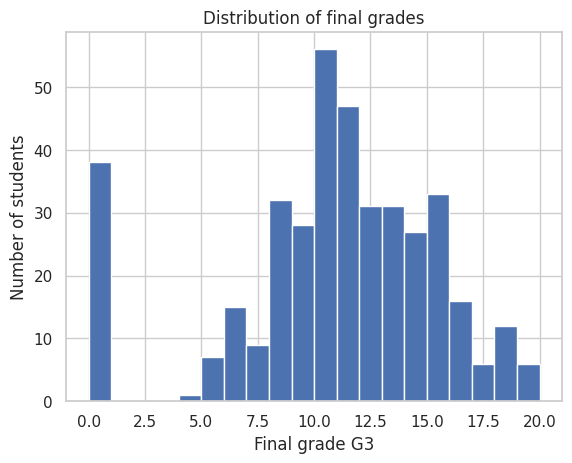

Average grade: 10.415189873417722
Students with grade 0: 38


In [171]:
# Cell 5: look at the target (final grade G3)
import matplotlib.pyplot as plt
df["G3"].hist(bins=20)
plt.xlabel("Final grade G3")
plt.ylabel("Number of students")
plt.title("Distribution of final grades")
plt.show()
print("Average grade:", df["G3"].mean())
print("Students with grade 0:", (df["G3"] == 0).sum())

In [172]:
# Cell 6: setup
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("student-mat.csv", sep=";")
df.shape

(395, 33)

In [173]:
# Cell 7: selecting
print(df["G3"].head())                       # one column
print(df[["age", "studytime", "G3"]].head()) # several columns
print(df.iloc[0])                            # first row by position
print(df.loc[0:4, ["sex", "age", "G3"]])     # rows 0-4, chosen columns

0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64
   age  studytime  G3
0   18          2   6
1   17          2   6
2   15          2  10
3   15          3  15
4   16          2  10
school             GP
sex                 F
age                18
address             U
famsize           GT3
Pstatus             A
Medu                4
Fedu                4
Mjob          at_home
Fjob          teacher
reason         course
guardian       mother
traveltime          2
studytime           2
failures            0
schoolsup         yes
famsup             no
paid               no
activities         no
nursery           yes
higher            yes
internet           no
romantic           no
famrel              4
freetime            3
goout               4
Dalc                1
Walc                1
health              3
absences            6
G1                  5
G2                  6
G3                  6
Name: 0, dtype: object
  sex  age  G3
0   F   18   6
1   F   17   6
2   F   15 

In [174]:
# Cell 8: filtering (conditions use & for AND, | for OR, each in brackets)
high_scorers = df[df["G3"] >= 15]
print("Students with G3 >= 15:", len(high_scorers))

focused = df[(df["failures"] == 0) & (df["studytime"] >= 3)]
print("No failures and studytime >= 3:", len(focused))
print("Their average G3:", focused["G3"].mean())

Students with G3 >= 15: 73
No failures and studytime >= 3: 80
Their average G3: 11.7875


In [175]:
# Cell 9: sorting
top10 = df.sort_values("G3", ascending=False)[["sex", "age", "studytime", "absences", "G3"]].head(10)
top10

,sex,age,studytime,absences,G3
47,M,16,4,4,20
286,F,18,3,5,19
374,F,18,3,0,19
110,M,15,1,6,19
8,M,15,2,0,19
113,M,15,1,10,19
91,F,15,1,4,18
42,M,15,2,2,18
36,M,15,3,2,18
104,M,15,2,0,18


In [176]:
# Cell 10: counting categories
print(df["sex"].value_counts())
print(df["school"].value_counts())
print(df["studytime"].value_counts().sort_index())

sex
F    208
M    187
Name: count, dtype: int64
school
GP    349
MS     46
Name: count, dtype: int64
studytime
1    105
2    198
3     65
4     27
Name: count, dtype: int64


In [177]:
# Cell 11: groupby, the most useful pandas tool
print(df.groupby("studytime")["G3"].mean())
print(df.groupby("sex")["G3"].mean())
print(df.groupby("failures")["G3"].agg(["count", "mean"]))

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64
sex
F     9.966346
M    10.914439
Name: G3, dtype: float64
          count       mean
failures                  
0           312  11.253205
1            50   8.120000
2            17   6.235294
3            16   5.687500


In [178]:
# Cell 12: creating a new column (pass = final grade of 10 or more)
df["passed"] = (df["G3"] >= 10).astype(int)
print(df["passed"].value_counts())
print("Pass rate:", df["passed"].mean())

passed
1    265
0    130
Name: count, dtype: int64
Pass rate: 0.6708860759493671


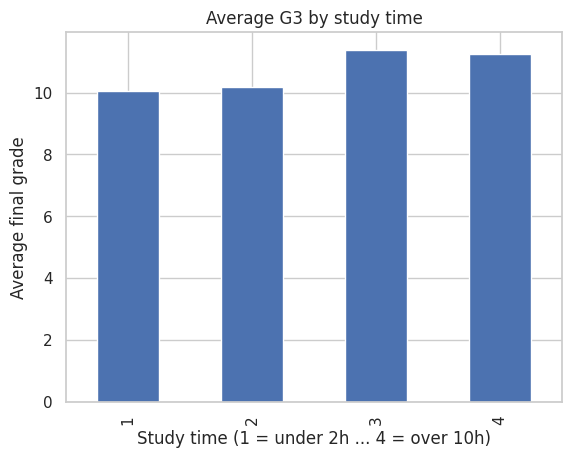

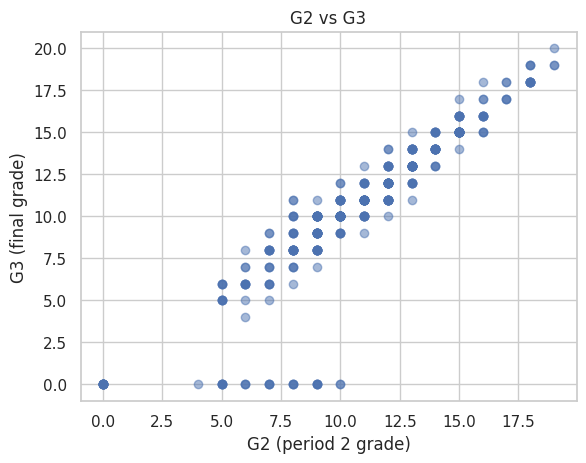

In [179]:
# Cell 13: two plots
df.groupby("studytime")["G3"].mean().plot(kind="bar")
plt.xlabel("Study time (1 = under 2h ... 4 = over 10h)")
plt.ylabel("Average final grade")
plt.title("Average G3 by study time")
plt.show()

plt.scatter(df["G2"], df["G3"], alpha=0.5)
plt.xlabel("G2 (period 2 grade)")
plt.ylabel("G3 (final grade)")
plt.title("G2 vs G3")
plt.show()

In [180]:
# Cell 14: a first look at correlation with the final grade
cols = ["G1", "G2", "G3", "studytime", "failures", "absences", "age"]
df[cols].corr()["G3"].sort_values(ascending=False)

,G3
G3,1.000000
G2,0.904868
G1,0.801468
studytime,0.097820
absences,0.034247
age,-0.161579
failures,-0.360415


In [181]:
# Cell 15: arrays, shape, data type
import numpy as np

a = np.array([1, 2, 3, 4, 5])
b = np.array([[1, 2, 3], [4, 5, 6]])

print(a, a.shape, a.dtype)
print(b)
print("b shape:", b.shape)

[1 2 3 4 5] (5,) int64
[[1 2 3]
 [4 5 6]]
b shape: (2, 3)


In [182]:
# Cell 16: creating arrays
print(np.zeros(4))
print(np.ones((2, 3)))
print(np.arange(0, 10, 2))
print(np.linspace(0, 1, 5))

np.random.seed(42)          # makes random numbers repeatable
print(np.random.randn(3))   # 3 random numbers from a normal distribution

[0. 0. 0. 0.]
[[1. 1. 1.]
 [1. 1. 1.]]
[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]
[ 0.49671415 -0.1382643   0.64768854]


In [183]:
# Cell 17: indexing and slicing
m = np.array([[10, 20, 30],
              [40, 50, 60],
              [70, 80, 90]])

print(m[0, 1])      # row 0, column 1 -> 20
print(m[:, 0])      # whole first column
print(m[1, :])      # whole second row
print(m[:2, 1:])    # top two rows, last two columns

20
[10 40 70]
[40 50 60]
[[20 30]
 [50 60]]


In [184]:
# Cell 18: vectorised operations vs loops
a = np.array([1, 2, 3, 4, 5])
print(a * 2)
print(a + 10)
print(a ** 2)
print(a + a)

# the slow way (a loop) gives the same answer
doubled = []
for x in a:
    doubled.append(x * 2)
print(doubled)

[ 2  4  6  8 10]
[11 12 13 14 15]
[ 1  4  9 16 25]
[ 2  4  6  8 10]
[np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10)]


In [185]:
# Cell 19: statistics and axis
grades = np.array([[12, 14, 15],
                   [8, 9, 10],
                   [16, 17, 18]])

print("Mean:", grades.mean())
print("Std:", grades.std())
print("Max:", grades.max(), "Min:", grades.min())
print("Mean of each column:", grades.mean(axis=0))   # axis=0 -> down the rows
print("Mean of each row:", grades.mean(axis=1))      # axis=1 -> across the columns

Mean: 13.222222222222221
Std: 3.424674446093876
Max: 18 Min: 8
Mean of each column: [12.         13.33333333 14.33333333]
Mean of each row: [13.66666667  9.         17.        ]


In [186]:
# Cell 20: dot product and matrix multiplication (the heart of ML)
# one student: studytime, failures, absences
student = np.array([3, 0, 6])
weights = np.array([1.5, -2.0, -0.1])
bias = 8

print("Prediction:", np.dot(student, weights) + bias)   # 11.9

# three students at once
students = np.array([[3, 0, 6],
                     [1, 2, 10],
                     [4, 0, 0]])
print("Predictions:", students @ weights + bias)        # [11.9  4.5  14.]

Prediction: 11.9
Predictions: [11.9  4.5 14. ]


In [187]:
# Cell 21: boolean masks and normalisation
scores = np.array([4, 9, 12, 15, 7, 18, 10])

print(scores >= 10)                    # True/False for each
print(scores[scores >= 10])            # only the passing scores
print("Pass count:", (scores >= 10).sum())

# z-score normalisation: mean 0, std 1
z = (scores - scores.mean()) / scores.std()
print(z.round(2))
print("New mean:", z.mean().round(4), "New std:", z.std().round(4))

[False False  True  True False  True  True]
[12 15 18 10]
Pass count: 4
[-1.53 -0.39  0.29  0.97 -0.84  1.66 -0.16]
New mean: 0.0 New std: 1.0


In [188]:
# Cell 22: from your DataFrame to NumPy
import pandas as pd
df = pd.read_csv("student-mat.csv", sep=";")   # upload the file again if Colab restarted

X = df[["studytime", "failures", "absences", "G1"]].values
y = df["G3"].values

print("X shape:", X.shape)    # (395, 4)
print("y shape:", y.shape)    # (395,)

# add a column of ones so the bias is learned like any other weight
X_b = np.c_[np.ones(len(X)), X]
print("X_b shape:", X_b.shape)   # (395, 5)

X shape: (395, 4)
y shape: (395,)
X_b shape: (395, 5)


In [189]:
# Cell 23: your first prediction and error metrics
np.random.seed(42)
w = np.random.randn(X_b.shape[1]) * 0.1   # 5 random weights

y_pred = X_b @ w
errors = y_pred - y

mse = np.mean(errors ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(errors))

print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("MAE :", round(mae, 2))

MSE : 118.02
RMSE: 10.86
MAE : 9.77


In [190]:
# Cell 24: setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("student-mat.csv", sep=";")
df.shape

(395, 33)

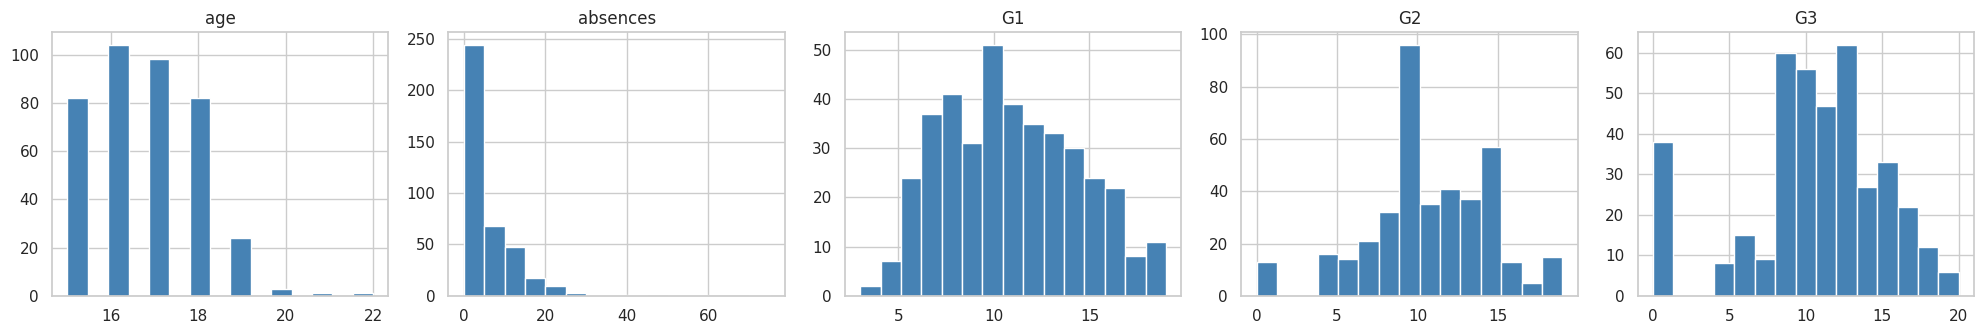

In [191]:
# Cell 25: histograms of key numeric columns
cols = ["age", "absences", "G1", "G2", "G3"]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, c in zip(axes, cols):
    ax.hist(df[c], bins=15, color="steelblue", edgecolor="white")
    ax.set_title(c)
plt.tight_layout()
plt.show()

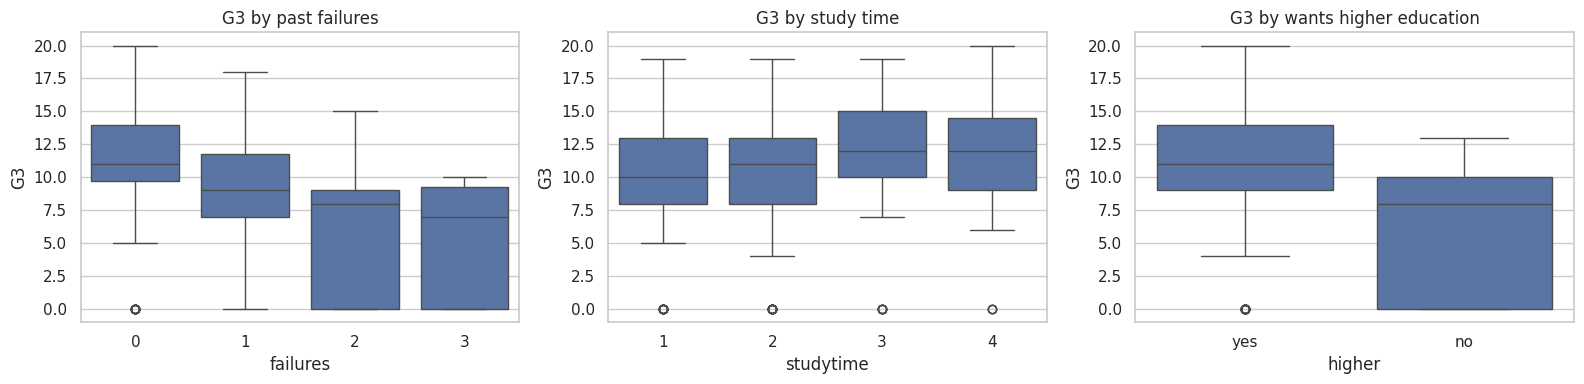

In [192]:
# Cell 26: box plots, G3 across groups
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(x="failures", y="G3", data=df, ax=axes[0])
sns.boxplot(x="studytime", y="G3", data=df, ax=axes[1])
sns.boxplot(x="higher", y="G3", data=df, ax=axes[2])
axes[0].set_title("G3 by past failures")
axes[1].set_title("G3 by study time")
axes[2].set_title("G3 by wants higher education")
plt.tight_layout()
plt.show()

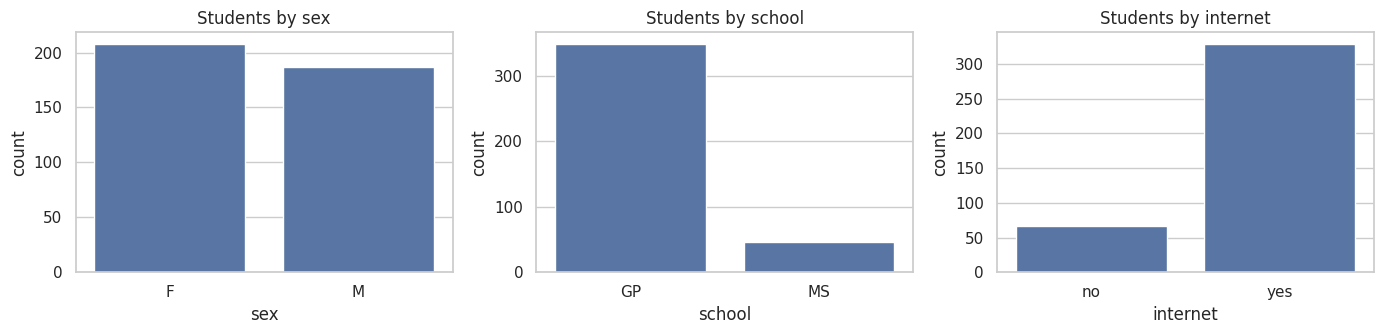

In [193]:
# Cell 27: category counts
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, ["sex", "school", "internet"]):
    sns.countplot(x=c, data=df, ax=ax)
    ax.set_title(f"Students by {c}")
plt.tight_layout()
plt.show()

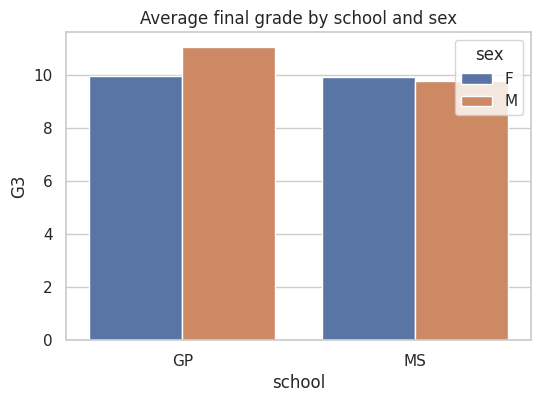

In [194]:
# Cell 28: average grade by two categories at once
plt.figure(figsize=(6, 4))
sns.barplot(x="school", y="G3", hue="sex", data=df, errorbar=None)
plt.title("Average final grade by school and sex")
plt.show()

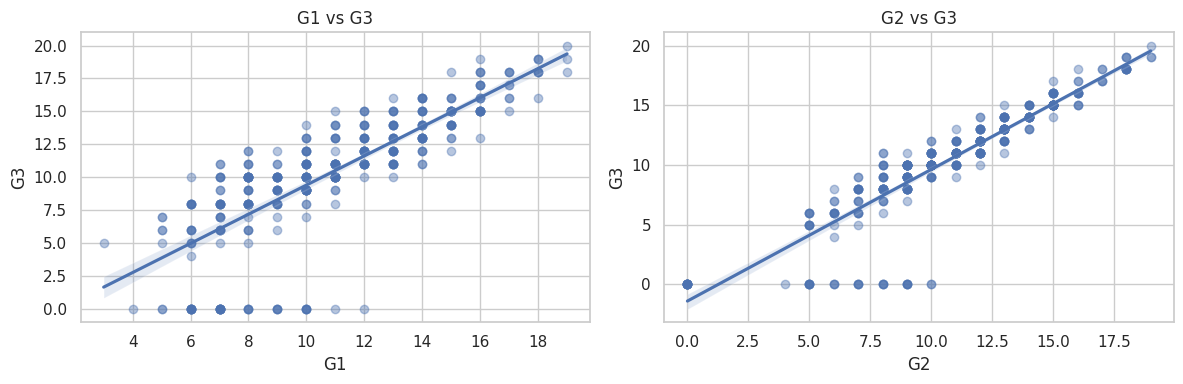

In [195]:
# Cell 29: scatter plots with a trend line
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(x="G1", y="G3", data=df, ax=axes[0], scatter_kws={"alpha": 0.4})
sns.regplot(x="G2", y="G3", data=df, ax=axes[1], scatter_kws={"alpha": 0.4})
axes[0].set_title("G1 vs G3")
axes[1].set_title("G2 vs G3")
plt.tight_layout()
plt.show()

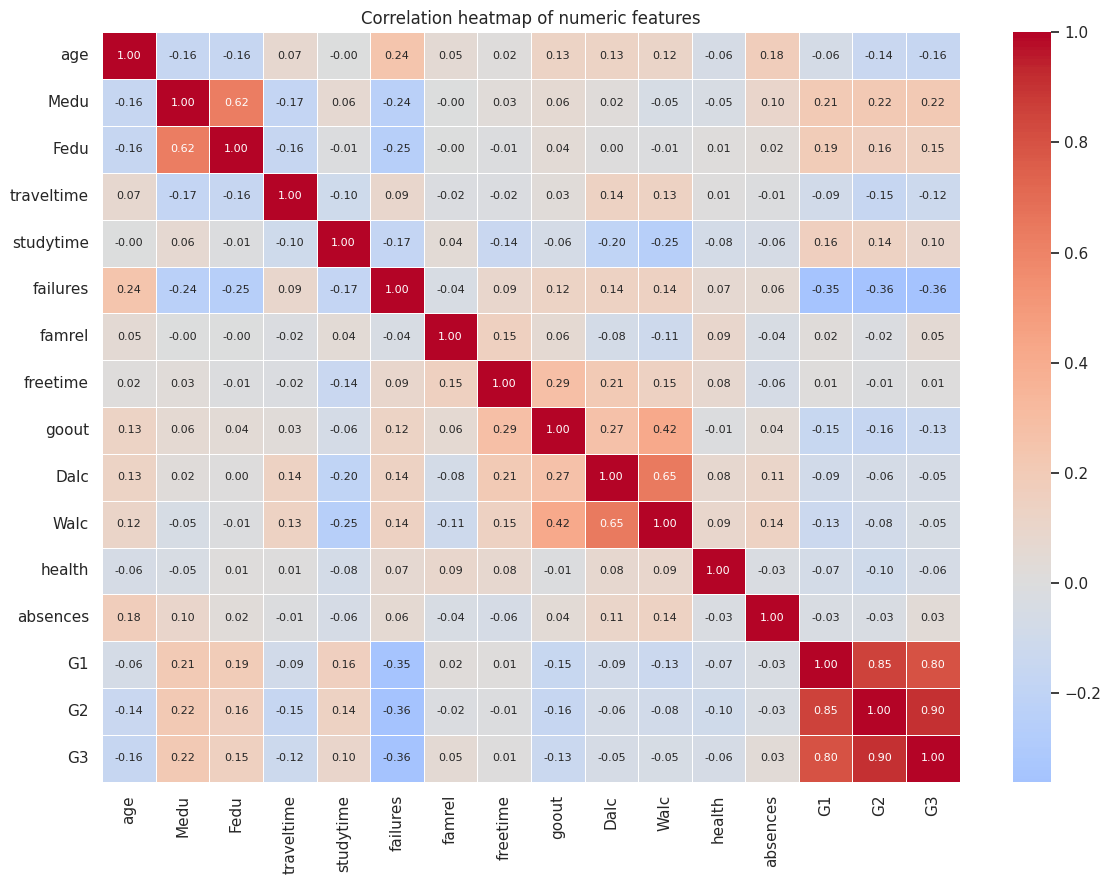

In [196]:
# Cell 30: the correlation heatmap
num = df.select_dtypes(include="number")
corr = num.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"size": 8}, linewidths=0.5)
plt.title("Correlation heatmap of numeric features")
plt.tight_layout()
plt.savefig("heatmap.png", dpi=150, bbox_inches="tight")   # saved for your report
plt.show()

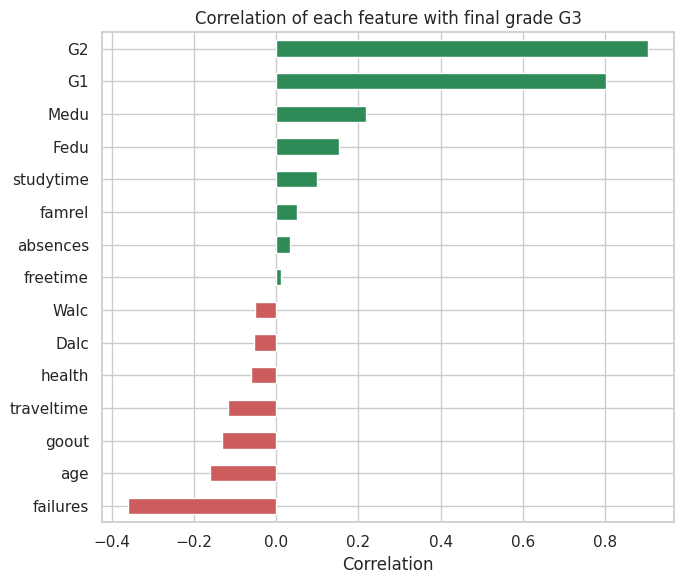

G2            0.90
G1            0.80
Medu          0.22
Fedu          0.15
studytime     0.10
famrel        0.05
absences      0.03
freetime      0.01
Walc         -0.05
Dalc         -0.05
health       -0.06
traveltime   -0.12
goout        -0.13
age          -0.16
failures     -0.36
Name: G3, dtype: float64


In [197]:
# Cell 31: which features correlate most with G3?
g3_corr = corr["G3"].drop("G3").sort_values()

plt.figure(figsize=(7, 6))
g3_corr.plot(kind="barh", color=np.where(g3_corr > 0, "seagreen", "indianred"))
plt.title("Correlation of each feature with final grade G3")
plt.xlabel("Correlation")
plt.tight_layout()
plt.savefig("g3_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

print(g3_corr.sort_values(ascending=False).round(2))

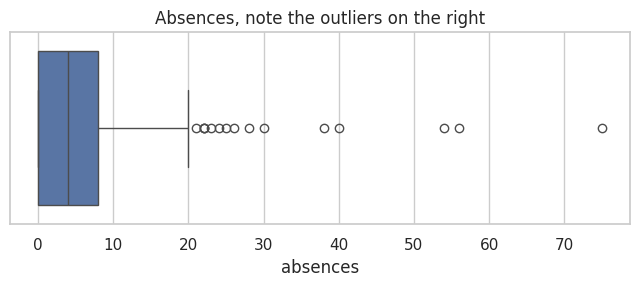

Students with G3 = 0: 38
Their average G2: 4.657894736842105
Their average absences: 0.0
Average absences of everyone else: 6.3165266106442575


In [198]:
# Cell 32: outliers and zero grades
plt.figure(figsize=(8, 2.5))
sns.boxplot(x=df["absences"])
plt.title("Absences, note the outliers on the right")
plt.show()

zeros = df[df["G3"] == 0]
print("Students with G3 = 0:", len(zeros))
print("Their average G2:", zeros["G2"].mean())
print("Their average absences:", zeros["absences"].mean())
print("Average absences of everyone else:", df[df["G3"] > 0]["absences"].mean())

In [199]:
# Cell 33: setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("student-mat.csv", sep=";")
print("Shape:", df.shape)

Shape: (395, 33)


In [200]:
# Cell 34: data types, split into numeric and categorical
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

print(f"Numeric columns ({len(num_cols)}):", num_cols)
print()
print(f"Categorical columns ({len(cat_cols)}):", cat_cols)

Numeric columns (16): ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Categorical columns (17): ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [201]:
# Cell 35: missing values and duplicates
print("Missing values per column (only showing columns with any):")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "None, the dataset is complete")

print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column (only showing columns with any):
None, the dataset is complete

Duplicate rows: 0


In [202]:
# Cell 36: what values do the categorical columns contain?
for c in cat_cols:
    print(f"{c:12s} -> {sorted(df[c].unique())}")

school       -> ['GP', 'MS']
sex          -> ['F', 'M']
address      -> ['R', 'U']
famsize      -> ['GT3', 'LE3']
Pstatus      -> ['A', 'T']
Mjob         -> ['at_home', 'health', 'other', 'services', 'teacher']
Fjob         -> ['at_home', 'health', 'other', 'services', 'teacher']
reason       -> ['course', 'home', 'other', 'reputation']
guardian     -> ['father', 'mother', 'other']
schoolsup    -> ['no', 'yes']
famsup       -> ['no', 'yes']
paid         -> ['no', 'yes']
activities   -> ['no', 'yes']
nursery      -> ['no', 'yes']
higher       -> ['no', 'yes']
internet     -> ['no', 'yes']
romantic     -> ['no', 'yes']


In [203]:
# Cell 37: outlier check using the IQR rule
def count_outliers(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < low) | (series > high)).sum()

outliers = pd.Series({c: count_outliers(df[c]) for c in num_cols}).sort_values(ascending=False)
print(outliers[outliers > 0])

failures      83
studytime     27
famrel        26
freetime      19
Dalc          18
absences      15
G2            13
traveltime     8
Fedu           2
age            1
dtype: int64


In [204]:
# Cell 38: build a data dictionary
descriptions = {
    "school": "School attended (GP or MS)",
    "sex": "Student's sex (F or M)",
    "age": "Age in years (15-22)",
    "address": "Home address type (U = urban, R = rural)",
    "famsize": "Family size (LE3 = 3 or fewer, GT3 = more than 3)",
    "Pstatus": "Parents living together (T) or apart (A)",
    "Medu": "Mother's education (0-4)",
    "Fedu": "Father's education (0-4)",
    "Mjob": "Mother's job category",
    "Fjob": "Father's job category",
    "reason": "Reason for choosing this school",
    "guardian": "Student's guardian",
    "traveltime": "Home to school travel time (1-4)",
    "studytime": "Weekly study time (1-4)",
    "failures": "Number of past class failures",
    "schoolsup": "Extra educational support from school",
    "famsup": "Family educational support",
    "paid": "Paid extra classes in the subject",
    "activities": "Extracurricular activities",
    "nursery": "Attended nursery school",
    "higher": "Wants to take higher education",
    "internet": "Internet access at home",
    "romantic": "In a romantic relationship",
    "famrel": "Quality of family relationships (1-5)",
    "freetime": "Free time after school (1-5)",
    "goout": "Going out with friends (1-5)",
    "Dalc": "Weekday alcohol consumption (1-5)",
    "Walc": "Weekend alcohol consumption (1-5)",
    "health": "Current health status (1-5)",
    "absences": "Number of school absences",
    "G1": "First period grade (0-20)",
    "G2": "Second period grade (0-20)",
    "G3": "Final grade (0-20), TARGET",
}

dictionary = pd.DataFrame({
    "column": df.columns,
    "type": ["numeric" if c in num_cols else "categorical" for c in df.columns],
    "description": [descriptions[c] for c in df.columns],
    "example": [df[c].iloc[0] for c in df.columns],
})
dictionary.to_csv("data_dictionary.csv", index=False)
dictionary

,column,type,description,example
0,school,categorical,School attended (GP or MS),GP
1,sex,categorical,Student's sex (F or M),F
2,age,numeric,Age in years (15-22),18
3,address,categorical,"Home address type (U = urban, R = rural)",U
4,famsize,categorical,"Family size (LE3 = 3 or fewer, GT3 = more than 3)",GT3
5,Pstatus,categorical,Parents living together (T) or apart (A),A
6,Medu,numeric,Mother's education (0-4),4
7,Fedu,numeric,Father's education (0-4),4
8,Mjob,categorical,Mother's job category,at_home
9,Fjob,categorical,Father's job category,teacher


In [205]:
# Cell 39: a one-screen summary of the dataset
summary = {
    "Rows": df.shape[0],
    "Columns": df.shape[1],
    "Numeric columns": len(num_cols),
    "Categorical columns": len(cat_cols),
    "Missing values": int(df.isnull().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Average final grade": round(df["G3"].mean(), 2),
    "Pass rate (G3 >= 10)": round((df["G3"] >= 10).mean(), 3),
    "Students with G3 = 0": int((df["G3"] == 0).sum()),
    "Correlation G2-G3": round(df["G2"].corr(df["G3"]), 2),
    "Correlation G1-G3": round(df["G1"].corr(df["G3"]), 2),
    "Correlation failures-G3": round(df["failures"].corr(df["G3"]), 2),
}
for k, v in summary.items():
    print(f"{k:28s}{v}")

Rows                        395
Columns                     33
Numeric columns             16
Categorical columns         17
Missing values              0
Duplicate rows              0
Average final grade         10.42
Pass rate (G3 >= 10)        0.671
Students with G3 = 0        38
Correlation G2-G3           0.9
Correlation G1-G3           0.8
Correlation failures-G3     -0.36


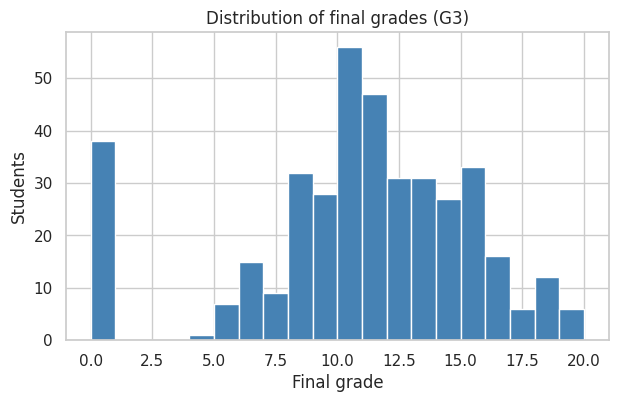

In [206]:
# Cell 40: save the three best figures for your report
fig, ax = plt.subplots(figsize=(7, 4))
df["G3"].hist(bins=20, ax=ax, color="steelblue", edgecolor="white")
ax.set_title("Distribution of final grades (G3)")
ax.set_xlabel("Final grade")
ax.set_ylabel("Students")
fig.savefig("g3_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [207]:
# Cell 41: setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
df = pd.read_csv("student-mat.csv", sep=";")
df["passed"] = (df["G3"] >= 10).astype(int)

groups = {
    "Study habits": ["studytime", "failures", "absences", "paid", "schoolsup", "higher"],
    "Family background": ["Medu", "Fedu", "famsup", "famrel", "Pstatus", "famsize"],
    "Lifestyle": ["goout", "freetime", "Dalc", "Walc", "romantic", "internet", "health"],
}
print("Groups defined:", {k: len(v) for k, v in groups.items()})

Groups defined: {'Study habits': 6, 'Family background': 6, 'Lifestyle': 7}


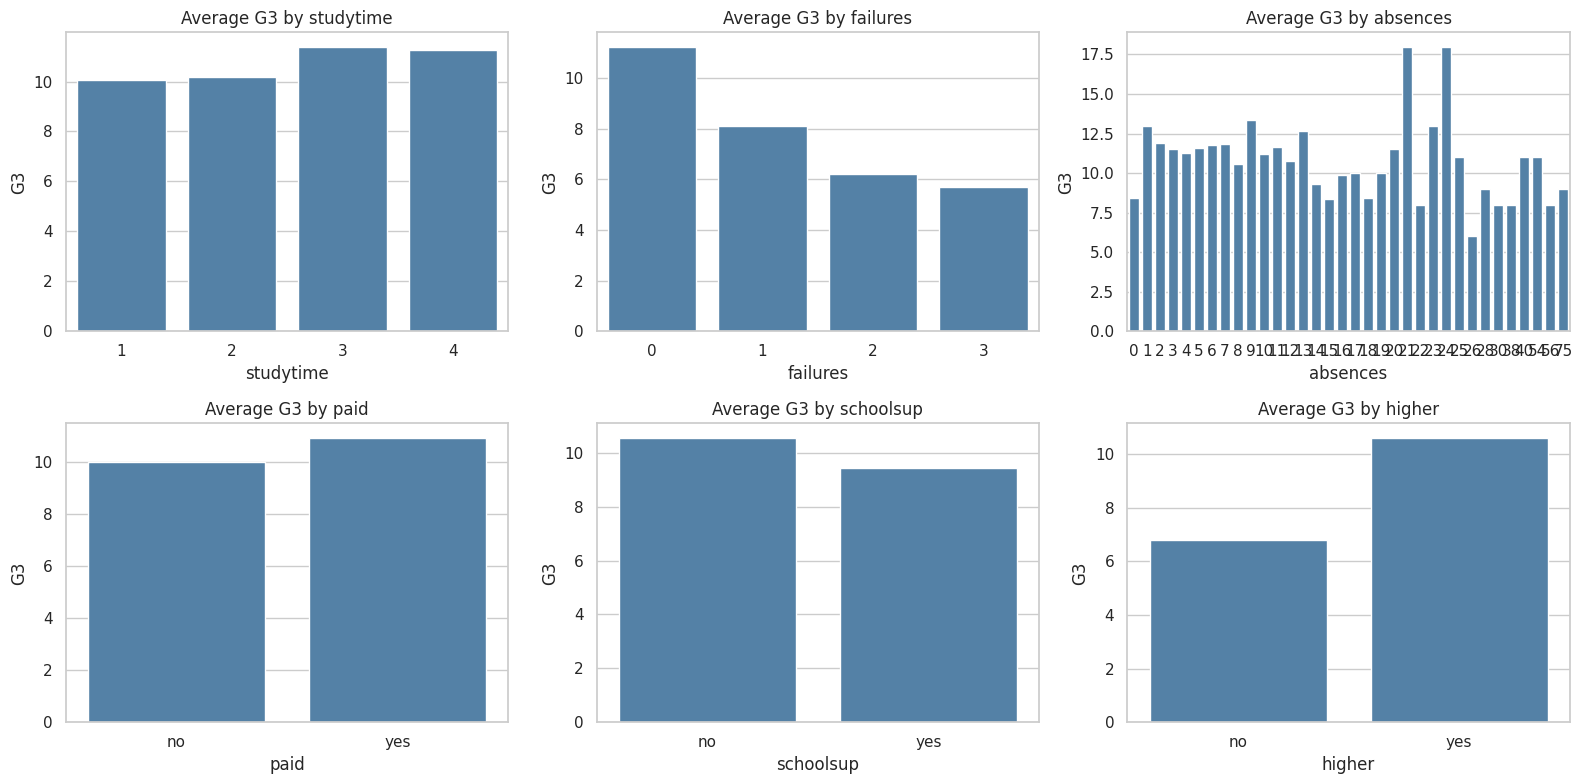

In [208]:
# Cell 42: study habits, average G3 and pass rate
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flat, groups["Study habits"]):
    order = sorted(df[c].unique())
    sns.barplot(x=c, y="G3", data=df, order=order, errorbar=None, ax=ax, color="steelblue")
    ax.set_title(f"Average G3 by {c}")
plt.tight_layout()
plt.savefig("eda_study_habits.png", dpi=150, bbox_inches="tight")
plt.show()

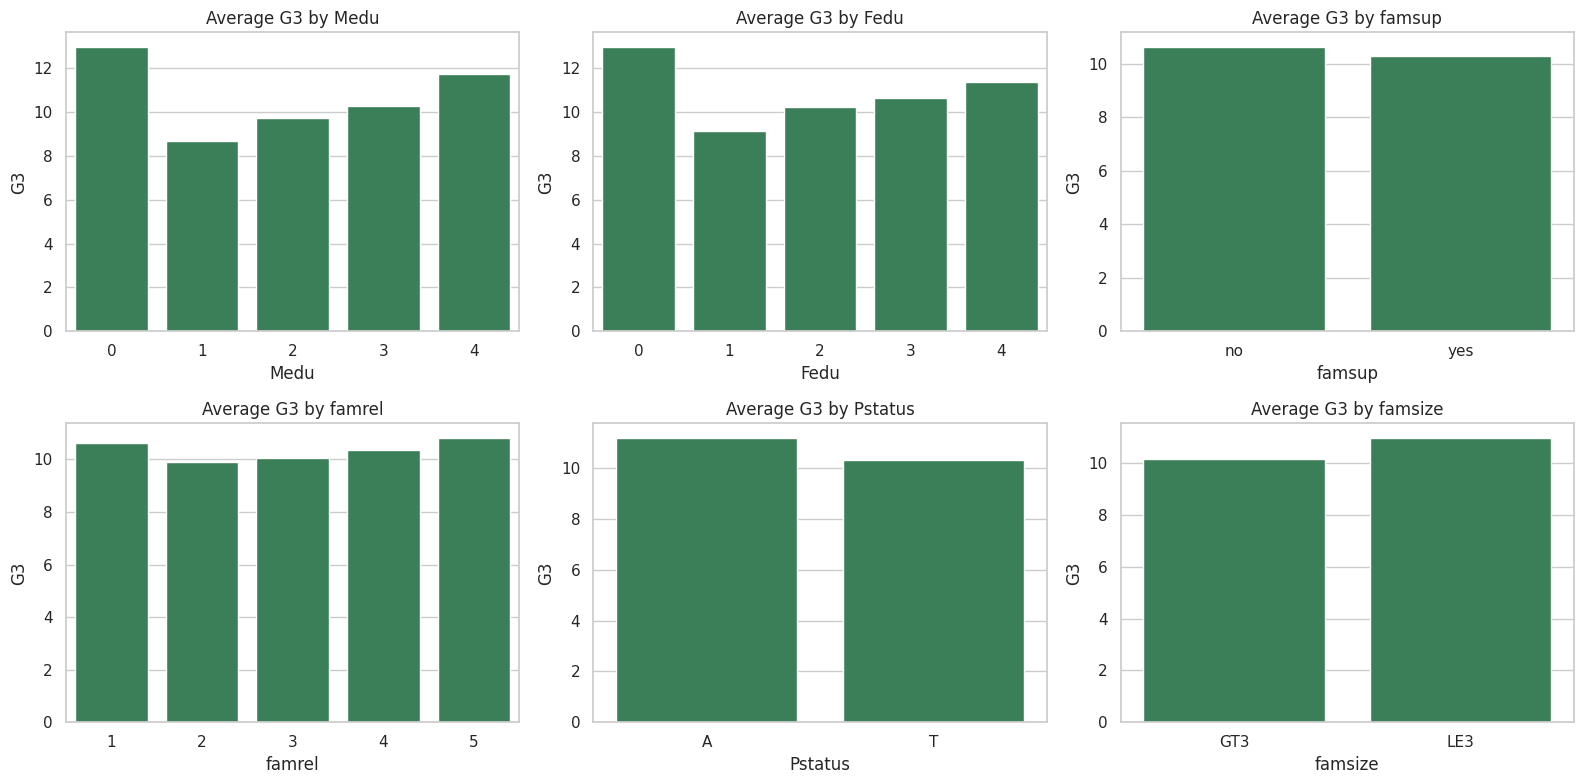

In [209]:
# Cell 43: family background
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flat, groups["Family background"]):
    order = sorted(df[c].unique())
    sns.barplot(x=c, y="G3", data=df, order=order, errorbar=None, ax=ax, color="seagreen")
    ax.set_title(f"Average G3 by {c}")
plt.tight_layout()
plt.savefig("eda_family.png", dpi=150, bbox_inches="tight")
plt.show()

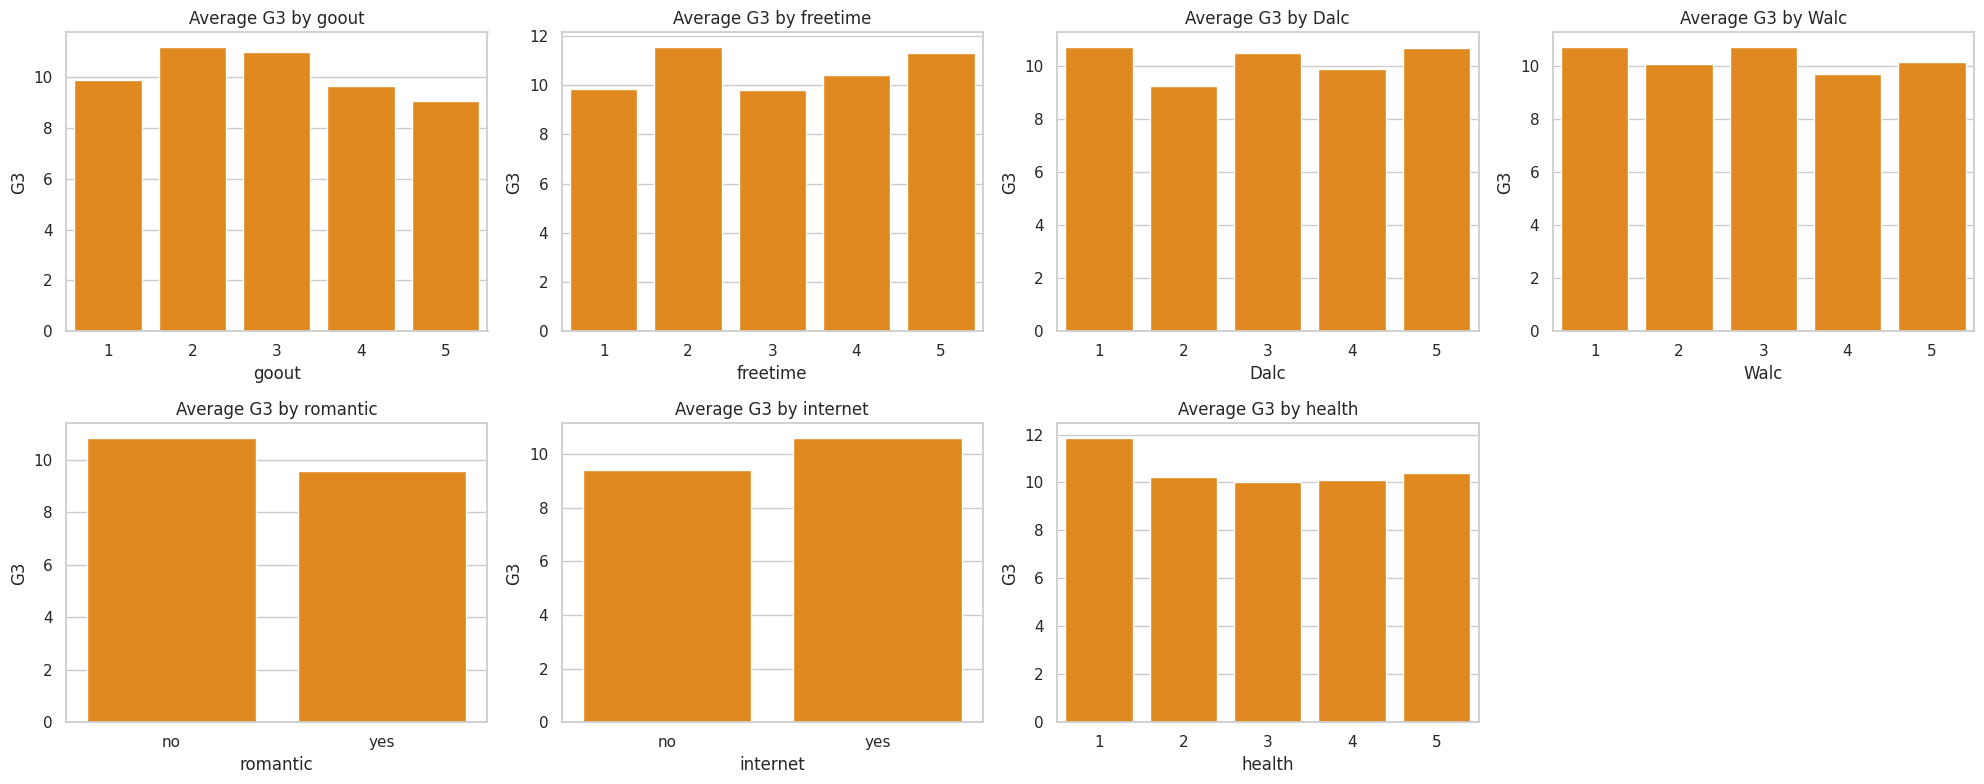

In [210]:
# Cell 44: lifestyle
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.flat, groups["Lifestyle"]):
    order = sorted(df[c].unique())
    sns.barplot(x=c, y="G3", data=df, order=order, errorbar=None, ax=ax, color="darkorange")
    ax.set_title(f"Average G3 by {c}")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig("eda_lifestyle.png", dpi=150, bbox_inches="tight")
plt.show()

In [211]:
# Cell 45: a reusable hypothesis-testing function
def compare(df, col, group_a, group_b, target="G3"):
    a = df[df[col] == group_a][target]
    b = df[df[col] == group_b][target]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    return {
        "feature": col,
        "group A": f"{group_a} (n={len(a)})",
        "group B": f"{group_b} (n={len(b)})",
        "mean A": round(a.mean(), 2),
        "mean B": round(b.mean(), 2),
        "difference": round(a.mean() - b.mean(), 2),
        "p-value": round(p, 4),
        "significant": "Yes" if p < 0.05 else "No",
    }

tests = [
    compare(df, "higher", "yes", "no"),
    compare(df, "internet", "yes", "no"),
    compare(df, "romantic", "yes", "no"),
    compare(df, "address", "U", "R"),
    compare(df, "paid", "yes", "no"),
    compare(df, "schoolsup", "yes", "no"),
    compare(df, "sex", "M", "F"),
    compare(df, "famsup", "yes", "no"),
]
results = pd.DataFrame(tests)
results

,feature,group A,group B,mean A,mean B,difference,p-value,significant
0,higher,yes (n=375),no (n=20),10.61,6.80,3.81,0.0024,Yes
1,internet,yes (n=329),no (n=66),10.62,9.41,1.21,0.0496,Yes
2,romantic,yes (n=132),no (n=263),9.58,10.84,-1.26,0.0127,Yes
3,address,U (n=307),R (n=88),10.67,9.51,1.16,0.0366,Yes
4,paid,yes (n=181),no (n=214),10.92,9.99,0.94,0.0379,Yes
5,schoolsup,yes (n=51),no (n=344),9.43,10.56,-1.13,0.0197,Yes
6,sex,M (n=187),F (n=208),10.91,9.97,0.95,0.0396,Yes
7,famsup,yes (n=242),no (n=153),10.27,10.64,-0.37,0.4398,No


In [212]:
# Cell 46: repeat the tests without the zero-grade students
df_nz = df[df["G3"] > 0]
print("Students kept:", len(df_nz), "of", len(df))

tests_nz = [
    compare(df_nz, "higher", "yes", "no"),
    compare(df_nz, "internet", "yes", "no"),
    compare(df_nz, "romantic", "yes", "no"),
    compare(df_nz, "address", "U", "R"),
    compare(df_nz, "paid", "yes", "no"),
    compare(df_nz, "schoolsup", "yes", "no"),
    compare(df_nz, "sex", "M", "F"),
    compare(df_nz, "famsup", "yes", "no"),
]
results_nz = pd.DataFrame(tests_nz)

side_by_side = results[["feature", "difference", "p-value"]].merge(
    results_nz[["feature", "difference", "p-value"]],
    on="feature", suffixes=(" (all)", " (no zeros)"))
side_by_side

Students kept: 357 of 395


,feature,difference (all),p-value (all),difference (no zeros),p-value (no zeros)
0,higher,3.81,0.0024,1.88,0.0028
1,internet,1.21,0.0496,0.98,0.0268
2,romantic,-1.26,0.0127,-0.35,0.3197
3,address,1.16,0.0366,1.01,0.0145
4,paid,0.94,0.0379,-0.19,0.5850
5,schoolsup,-1.13,0.0197,-2.21,0.0000
6,sex,0.95,0.0396,0.66,0.0533
7,famsup,-0.37,0.4398,-0.45,0.2023


In [213]:
# Cell 47: correlation of ordinal features with G3, by group
rows = []
for g, cols in groups.items():
    for c in cols:
        if pd.api.types.is_numeric_dtype(df[c]):
            rows.append({"group": g, "feature": c, "correlation with G3": round(df[c].corr(df["G3"]), 3)})
corr_table = pd.DataFrame(rows).sort_values("correlation with G3")
corr_table

,group,feature,correlation with G3
1,Study habits,failures,-0.360
6,Lifestyle,goout,-0.133
10,Lifestyle,health,-0.061
8,Lifestyle,Dalc,-0.055
9,Lifestyle,Walc,-0.052
7,Lifestyle,freetime,0.011
2,Study habits,absences,0.034
5,Family background,famrel,0.051
0,Study habits,studytime,0.098
4,Family background,Fedu,0.152


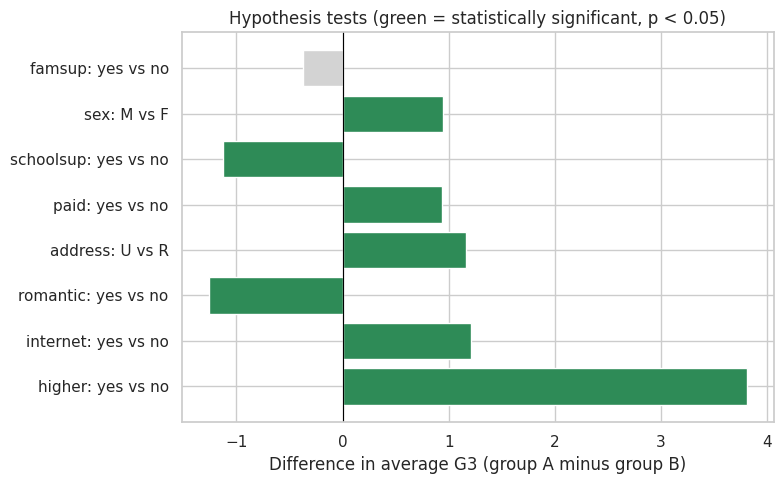

In [214]:
# Cell 48: one summary figure for your report
plot_df = results.copy()
plot_df["label"] = plot_df["feature"] + ": " + plot_df["group A"].str.split(" ").str[0] + " vs " + plot_df["group B"].str.split(" ").str[0]
colors = ["seagreen" if s == "Yes" else "lightgray" for s in plot_df["significant"]]

plt.figure(figsize=(8, 5))
plt.barh(plot_df["label"], plot_df["difference"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Difference in average G3 (group A minus group B)")
plt.title("Hypothesis tests (green = statistically significant, p < 0.05)")
plt.tight_layout()
plt.savefig("hypothesis_tests.png", dpi=150, bbox_inches="tight")
plt.show()

In [215]:
# Cell 49: setup and a look at what needs encoding
import pandas as pd
import numpy as np

df = pd.read_csv("student-mat.csv", sep=";")
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Categorical columns:", len(cat_cols))
for c in cat_cols:
    print(f"{c:12s} {df[c].nunique()} values -> {sorted(df[c].unique())}")

Categorical columns: 17
school       2 values -> ['GP', 'MS']
sex          2 values -> ['F', 'M']
address      2 values -> ['R', 'U']
famsize      2 values -> ['GT3', 'LE3']
Pstatus      2 values -> ['A', 'T']
Mjob         5 values -> ['at_home', 'health', 'other', 'services', 'teacher']
Fjob         5 values -> ['at_home', 'health', 'other', 'services', 'teacher']
reason       4 values -> ['course', 'home', 'other', 'reputation']
guardian     3 values -> ['father', 'mother', 'other']
schoolsup    2 values -> ['no', 'yes']
famsup       2 values -> ['no', 'yes']
paid         2 values -> ['no', 'yes']
activities   2 values -> ['no', 'yes']
nursery      2 values -> ['no', 'yes']
higher       2 values -> ['no', 'yes']
internet     2 values -> ['no', 'yes']
romantic     2 values -> ['no', 'yes']


In [216]:
# Cell 50: split the categorical columns into binary and nominal
binary_cols = [c for c in cat_cols if df[c].nunique() == 2]
nominal_cols = [c for c in cat_cols if df[c].nunique() > 2]

print("Binary :", binary_cols)
print("Nominal:", nominal_cols)

Binary : ['school', 'sex', 'address', 'famsize', 'Pstatus', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Nominal: ['Mjob', 'Fjob', 'reason', 'guardian']


In [217]:
# Cell 51: binary encoding with explicit, readable mappings
binary_maps = {
    "school":  {"GP": 0, "MS": 1},
    "sex":     {"F": 0, "M": 1},
    "address": {"R": 0, "U": 1},
    "famsize": {"LE3": 0, "GT3": 1},
    "Pstatus": {"A": 0, "T": 1},
}
yes_no_cols = ["schoolsup", "famsup", "paid", "activities",
               "nursery", "higher", "internet", "romantic"]
for c in yes_no_cols:
    binary_maps[c] = {"no": 0, "yes": 1}

df_enc = df.copy()
for col, mapping in binary_maps.items():
    df_enc[col] = df_enc[col].map(mapping)

# safety check: a wrong mapping would leave NaN behind
print("NaN after binary mapping:", df_enc[list(binary_maps)].isnull().sum().sum())
df_enc[list(binary_maps)].head()

NaN after binary mapping: 0


,school,sex,address,famsize,Pstatus,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
0,0,0,1,1,0,1,0,0,0,1,1,0,0
1,0,0,1,1,1,0,1,0,0,0,1,1,0
2,0,0,1,0,1,1,0,1,0,1,1,1,0
3,0,0,1,1,1,0,1,1,1,1,1,1,1
4,0,0,1,1,1,0,1,1,0,1,1,0,0


In [218]:
# Cell 52: one-hot encoding for nominal columns
df_enc = pd.get_dummies(df_enc, columns=nominal_cols, drop_first=True, dtype=int)

print("Shape after encoding:", df_enc.shape)
print("New columns:")
print([c for c in df_enc.columns if any(c.startswith(n + "_") for n in nominal_cols)])

Shape after encoding: (395, 42)
New columns:
['Mjob_health', 'Mjob_other', 'Mjob_services', 'Mjob_teacher', 'Fjob_health', 'Fjob_other', 'Fjob_services', 'Fjob_teacher', 'reason_home', 'reason_other', 'reason_reputation', 'guardian_mother', 'guardian_other']


In [219]:
# Cell 53: see what one-hot encoding did to a few rows
before = df[["Mjob", "guardian"]].head(5)
after = df_enc[[c for c in df_enc.columns if c.startswith(("Mjob_", "guardian_"))]].head(5)
print(before, "\n")
print(after)

      Mjob guardian
0  at_home   mother
1  at_home   father
2  at_home   mother
3   health   mother
4    other   father 

   Mjob_health  Mjob_other  Mjob_services  Mjob_teacher  guardian_mother  \
0            0           0              0             0                1   
1            0           0              0             0                0   
2            0           0              0             0                1   
3            1           0              0             0                1   
4            0           1              0             0                0   

   guardian_other  
0               0  
1               0  
2               0  
3               0  
4               0  


In [220]:
# Cell 54: validate, because a model will crash on any leftover text
print("Any non-numeric columns left:", len(df_enc.select_dtypes(exclude="number").columns))
print("Total missing values       :", df_enc.isnull().sum().sum())
print("Final shape (rows, columns):", df_enc.shape)
print("Features (excluding G3)    :", df_enc.shape[1] - 1)

Any non-numeric columns left: 0
Total missing values       : 0
Final shape (rows, columns): (395, 42)
Features (excluding G3)    : 41


In [221]:
# Cell 55: did encoding reveal anything new? Correlation of the new columns with G3
corr_new = df_enc.corr()["G3"].drop("G3").sort_values()

print("Most negative:")
print(corr_new.head(6).round(3))
print("\nMost positive (excluding G1, G2):")
print(corr_new.drop(["G1", "G2"]).tail(6).round(3))

Most negative:
failures     -0.360
age          -0.162
goout        -0.133
romantic     -0.130
traveltime   -0.117
Mjob_other   -0.096
Name: G3, dtype: float64

Most positive (excluding G1, G2):
sex            0.103
address        0.106
Mjob_health    0.116
Fedu           0.152
higher         0.182
Medu           0.217
Name: G3, dtype: float64


In [222]:
# Cell 56: the same job with scikit-learn (this is how it appears in a real pipeline)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

X = df.drop(columns="G3")
y = df["G3"]

preprocess = ColumnTransformer(
    transformers=[
        ("binary", OrdinalEncoder(), binary_cols),
        ("nominal", OneHotEncoder(drop="first", sparse_output=False), nominal_cols),
    ],
    remainder="passthrough",   # keep the numeric columns as they are
)

X_arr = preprocess.fit_transform(X)
print("Shape from the scikit-learn pipeline:", X_arr.shape)
print("Same number of features as the pandas version?", X_arr.shape[1] == df_enc.shape[1] - 1)

Shape from the scikit-learn pipeline: (395, 41)
Same number of features as the pandas version? True


In [223]:
# Cell 57: save the encoded dataset for the next days
df_enc.to_csv("student_encoded.csv", index=False)
print("Saved student_encoded.csv", df_enc.shape)

Saved student_encoded.csv (395, 42)


In [224]:
# Cell 58: setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("student-mat.csv", sep=";")           # original, readable
enc = pd.read_csv("student_encoded.csv")               # encoded, from Day 7
print(df.shape, enc.shape)

(395, 33) (395, 42)


In [225]:
# Cell 59: how many zero-grade students, and what do they look like?
df["zero_grade"] = (df["G3"] == 0)
print("Students with G3 = 0:", df["zero_grade"].sum(), "of", len(df))
print()
print(df[df["zero_grade"]][["G1", "G2", "G3", "absences", "failures"]].describe().round(2))

Students with G3 = 0: 38 of 395

          G1     G2    G3  absences  failures
count  38.00  38.00  38.0      38.0     38.00
mean    7.53   4.66   0.0       0.0      0.92
std     1.81   3.70   0.0       0.0      1.08
min     4.00   0.00   0.0       0.0      0.00
25%     6.00   0.00   0.0       0.0      0.00
50%     7.00   5.00   0.0       0.0      1.00
75%     9.00   8.00   0.0       0.0      1.75
max    12.00  10.00   0.0       0.0      3.00


In [226]:
# Cell 60: are zeros linked to a zero in G2? absences?
print("G2 = 0 vs G3 = 0:")
print(pd.crosstab(df["G2"] == 0, df["G3"] == 0, rownames=["G2 == 0"], colnames=["G3 == 0"]))
print()
print("Absences of zero-grade students:")
print(df[df["zero_grade"]]["absences"].value_counts().sort_index())
print()
print("Average absences, zero-grade vs others:")
print(df.groupby("zero_grade")["absences"].mean().round(2))

G2 = 0 vs G3 = 0:
G3 == 0  False  True 
G2 == 0              
False      357     25
True         0     13

Absences of zero-grade students:
absences
0    38
Name: count, dtype: int64

Average absences, zero-grade vs others:
zero_grade
False    6.32
True     0.00
Name: absences, dtype: float64


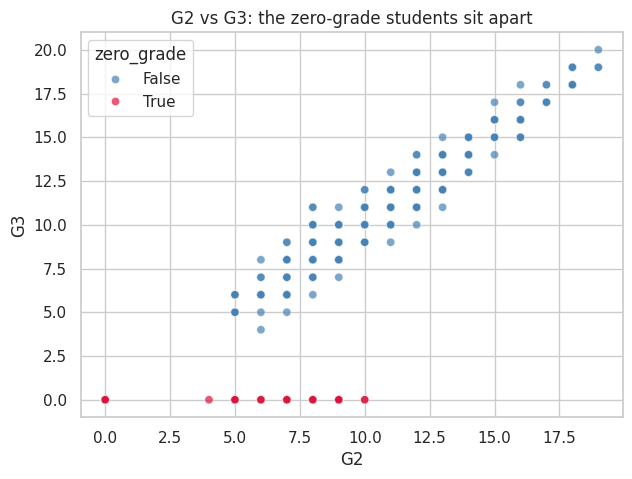

In [227]:
# Cell 61: see the zeros on the G2 vs G3 chart
plt.figure(figsize=(7, 5))
sns.scatterplot(x="G2", y="G3", hue="zero_grade", data=df, alpha=0.7,
                palette={False: "steelblue", True: "crimson"})
plt.title("G2 vs G3: the zero-grade students sit apart")
plt.savefig("zero_grade_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

In [228]:
# Cell 62: do zero-grade students differ on other features?
compare_cols = ["age", "failures", "studytime", "Medu", "Fedu", "goout", "G1"]
print(df.groupby("zero_grade")[compare_cols].mean().round(2).T)

zero_grade  False  True 
age         16.66  17.08
failures     0.27   0.92
studytime    2.04   1.97
Medu         2.80   2.32
Fedu         2.55   2.29
goout        3.10   3.21
G1          11.27   7.53


In [229]:
# Cell 63: absences outliers using the IQR rule
q1, q3 = df["absences"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr

print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}, upper fence = {upper}")
print("Students above the fence:", (df["absences"] > upper).sum())
print("Largest absence counts:", sorted(df["absences"].unique())[-6:])
print()
print(df["absences"].describe().round(2))

Q1 = 0.0, Q3 = 8.0, IQR = 8.0, upper fence = 20.0
Students above the fence: 15
Largest absence counts: [np.int64(30), np.int64(38), np.int64(40), np.int64(54), np.int64(56), np.int64(75)]

count    395.00
mean       5.71
std        8.00
min        0.00
25%        0.00
50%        4.00
75%        8.00
max       75.00
Name: absences, dtype: float64


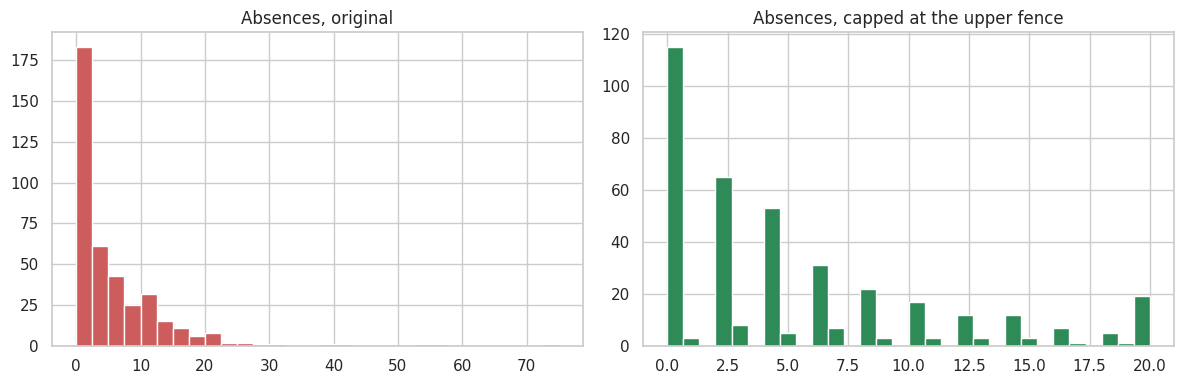

Correlation with G3 (original): 0.034
Correlation with G3 (capped)  : 0.068


In [230]:
# Cell 64: cap absences at the upper fence, and compare before/after
df["absences_capped"] = df["absences"].clip(upper=upper)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["absences"], bins=30, color="indianred", edgecolor="white")
axes[0].set_title("Absences, original")
axes[1].hist(df["absences_capped"], bins=30, color="seagreen", edgecolor="white")
axes[1].set_title("Absences, capped at the upper fence")
plt.tight_layout()
plt.savefig("absences_capping.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlation with G3 (original):", round(df["absences"].corr(df["G3"]), 3))
print("Correlation with G3 (capped)  :", round(df["absences_capped"].corr(df["G3"]), 3))

In [231]:
# Cell 65: other outlier candidates, look but do not change
for c in ["age", "failures", "traveltime"]:
    print(f"{c:10s}", df[c].value_counts().sort_index().to_dict())

age        {15: 82, 16: 104, 17: 98, 18: 82, 19: 24, 20: 3, 21: 1, 22: 1}
failures   {0: 312, 1: 50, 2: 17, 3: 16}
traveltime {1: 257, 2: 107, 3: 23, 4: 8}


In [232]:
# Cell 66: does the zero-grade decision really matter? A fair test.
# Both training choices are scored on the SAME test students (graded ones only).
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

X = enc.drop(columns="G3")
y = enc["G3"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

graded = y_test > 0
X_test_g, y_test_g = X_test[graded], y_test[graded]

rows = []
for train_name, mask in [("train WITH zeros", y_train >= 0),
                         ("train WITHOUT zeros", y_train > 0)]:
    for feat_name, drop in [("all features", []),
                            ("without G1, G2", ["G1", "G2"])]:
        model = LinearRegression().fit(X_train[mask].drop(columns=drop), y_train[mask])
        pred = model.predict(X_test_g.drop(columns=drop))
        rows.append({
            "training data": train_name,
            "features": feat_name,
            "RMSE": round(np.sqrt(mean_squared_error(y_test_g, pred)), 2),
            "MAE": round(mean_absolute_error(y_test_g, pred), 2),
        })

pd.DataFrame(rows)

,training data,features,RMSE,MAE
0,train WITH zeros,all features,1.65,1.31
1,train WITH zeros,"without G1, G2",3.62,3.02
2,train WITHOUT zeros,all features,0.93,0.73
3,train WITHOUT zeros,"without G1, G2",3.14,2.61


In [233]:
# Cell 67: build and save the cleaned dataset
clean = enc[enc["G3"] > 0].copy()
clean["absences"] = clean["absences"].clip(upper=upper)

print("Original rows:", len(enc))
print("Rows removed (G3 = 0):", len(enc) - len(clean))
print("Clean shape:", clean.shape)
print("Absences max now:", clean["absences"].max())

clean.to_csv("student_clean.csv", index=False)

Original rows: 395
Rows removed (G3 = 0): 38
Clean shape: (357, 42)
Absences max now: 20


In [234]:
# Cell 68: setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv("student_clean.csv")
print("Shape:", df.shape)       # about 357 rows: 395 minus the zero-grade students

X = df.drop(columns="G3")
y = df["G3"]
X_early = X.drop(columns=["G1", "G2"])    # for early-warning use
print("Features, all:", X.shape[1], "| early (no G1/G2):", X_early.shape[1])

Shape: (357, 42)
Features, all: 41 | early (no G1/G2): 39


In [235]:
# Cell 69: the train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Average G3, train:", round(y_train.mean(), 2), "| test:", round(y_test.mean(), 2))

# same rows, early-warning feature set
X_train_e = X_train.drop(columns=["G1", "G2"])
X_test_e = X_test.drop(columns=["G1", "G2"])

Train: (285, 41) | Test: (72, 41)
Average G3, train: 11.55 | test: 11.43


In [236]:
# Cell 70: a helper that reports train and test performance
def report(model, Xtr, Xte, name):
    model.fit(Xtr, y_train)
    rows = {}
    for label, Xs, ys in [("train", Xtr, y_train), ("test", Xte, y_test)]:
        pred = model.predict(Xs)
        rows[label] = {"RMSE": round(np.sqrt(mean_squared_error(ys, pred)), 2),
                       "R2": round(r2_score(ys, pred), 3)}
    print(f"{name:34s} train RMSE {rows['train']['RMSE']:5.2f} R2 {rows['train']['R2']:6.3f}"
          f" | test RMSE {rows['test']['RMSE']:5.2f} R2 {rows['test']['R2']:6.3f}")

In [237]:
# Cell 71: overfitting, seen with your own eyes (early-warning features)
report(LinearRegression(), X_train_e, X_test_e, "Linear regression")
report(DecisionTreeRegressor(random_state=42), X_train_e, X_test_e, "Deep decision tree (no limit)")
report(DecisionTreeRegressor(max_depth=3, random_state=42), X_train_e, X_test_e, "Shallow tree (max_depth=3)")

Linear regression                  train RMSE  2.62 R2  0.349 | test RMSE  2.73 R2  0.227
Deep decision tree (no limit)      train RMSE  0.00 R2  1.000 | test RMSE  3.53 R2 -0.292
Shallow tree (max_depth=3)         train RMSE  2.87 R2  0.222 | test RMSE  2.88 R2  0.138


In [238]:
# Cell 72: data leakage, the wrong way vs the right way
# WRONG: scaler sees every student, including the test ones
scaler_wrong = StandardScaler().fit(X[["absences"]])
# RIGHT: scaler learns only from training students
scaler_right = StandardScaler().fit(X_train[["absences"]])

print("What each scaler learned about absences")
print(f"  WRONG (all data)    mean {scaler_wrong.mean_[0]:.4f}  std {scaler_wrong.scale_[0]:.4f}")
print(f"  RIGHT (train only)  mean {scaler_right.mean_[0]:.4f}  std {scaler_right.scale_[0]:.4f}")

test_scaled = scaler_right.transform(X_test[["absences"]])
print("\nTest set after the RIGHT scaler: mean", round(test_scaled.mean(), 3),
      "(not exactly 0, and that is correct and honest)")

What each scaler learned about absences
  WRONG (all data)    mean 5.7395  std 5.7113
  RIGHT (train only)  mean 5.6351  std 5.7339

Test set after the RIGHT scaler: mean 0.09 (not exactly 0, and that is correct and honest)


In [239]:
# Cell 73: only scale numeric columns, not 0/1 columns
scale_cols = [c for c in X.columns if X[c].nunique() > 2]
binary_cols = [c for c in X.columns if X[c].nunique() <= 2]
print("Scaled columns:", len(scale_cols), "->", scale_cols)
print("Left as 0/1   :", len(binary_cols))

prep = ColumnTransformer(
    [("scale", StandardScaler(), scale_cols)],
    remainder="passthrough")

Scaled columns: 15 -> ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']
Left as 0/1   : 26


In [240]:
# Cell 74: a pipeline bundles scaling and the model, so leakage cannot happen
pipe = Pipeline([("prep", prep), ("model", LinearRegression())])

report(pipe, X_train, X_test, "Linear regression, all features")

Linear regression, all features    train RMSE  0.75 R2  0.946 | test RMSE  0.90 R2  0.916


In [241]:
# Cell 75: what scaling gives you, comparable coefficients
feature_names = scale_cols + binary_cols     # ColumnTransformer output order
coefs = pd.Series(pipe.named_steps["model"].coef_, index=feature_names)

print("Largest effects on G3 (scaled features, so directly comparable):")
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(8).round(3))

Largest effects on G3 (scaled features, so directly comparable):
G2                2.803
guardian_other   -0.480
Mjob_teacher      0.428
G1                0.376
Pstatus          -0.296
Mjob_health       0.245
nursery          -0.233
Mjob_other       -0.221
dtype: float64


In [242]:
# Cell 76: cross-validation for a trustworthy score
cv = KFold(n_splits=5, shuffle=True, random_state=42)

for name, Xtr in [("all features", X_train), ("early (no G1/G2)", X_train_e)]:
    sc_cols = [c for c in Xtr.columns if X[c].nunique() > 2]
    p = Pipeline([
        ("prep", ColumnTransformer([("s", StandardScaler(), sc_cols)], remainder="passthrough")),
        ("model", LinearRegression())])
    scores = -cross_val_score(p, Xtr, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    print(f"{name:18s} RMSE per fold {scores.round(2)} | mean {scores.mean():.2f} +/- {scores.std():.2f}")

all features       RMSE per fold [0.96 0.92 0.84 0.79 1.01] | mean 0.91 +/- 0.08
early (no G1/G2)   RMSE per fold [3.12 3.09 3.16 2.72 3.17] | mean 3.05 +/- 0.17


In [243]:
# Cell 77: how much does the test score depend on luck? (different random splits)
results = []
for seed in range(10):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed)
    p = Pipeline([("prep", prep), ("model", LinearRegression())]).fit(Xtr, ytr)
    results.append(np.sqrt(mean_squared_error(yte, p.predict(Xte))))

print("Test RMSE across 10 different splits:", np.round(results, 2))
print(f"Range: {min(results):.2f} to {max(results):.2f}")

Test RMSE across 10 different splits: [0.96 0.88 0.85 0.88 0.85 0.85 0.89 0.84 0.87 0.97]
Range: 0.84 to 0.97


In [244]:
# Cell 78: save the official split used for the rest of the project
train = X_train.copy(); train["G3"] = y_train
test = X_test.copy();  test["G3"] = y_test
train.to_csv("train.csv", index=False)
test.to_csv("test.csv", index=False)
print("Saved train.csv", train.shape, "and test.csv", test.shape)

Saved train.csv (285, 42) and test.csv (72, 42)


In [245]:
# Cell 79: setup
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
print("Train:", train.shape, "| Test:", test.shape)

Train: (285, 42) | Test: (72, 42)


In [246]:
%%writefile features.py
# Cell 80: one reusable function. Your Streamlit app will import this on Day 25.
import pandas as pd

def add_features(df):
    out = df.copy()
    out["avg_parent_edu"] = (out["Medu"] + out["Fedu"]) / 2
    out["support_score"] = out["famsup"] + out["schoolsup"] + out["paid"]
    out["alcohol_avg"] = (out["Dalc"] + out["Walc"]) / 2
    out["social_load"] = out["goout"] + out["freetime"]
    out["has_failures"] = (out["failures"] > 0).astype(int)
    out["no_absences"] = (out["absences"] == 0).astype(int)
    if {"G1", "G2"}.issubset(out.columns):
        out["grade_trend"] = out["G2"] - out["G1"]
    return out

Overwriting features.py


In [247]:
# Cell 81: apply the same function to train and test
from features import add_features

train_fe = add_features(train)
test_fe = add_features(test)

new_cols = [c for c in train_fe.columns if c not in train.columns]
print("New features:", new_cols)
print("Train shape now:", train_fe.shape, "| Test shape now:", test_fe.shape)
train_fe[new_cols].describe().round(2)

New features: ['avg_parent_edu', 'support_score', 'alcohol_avg', 'social_load', 'has_failures', 'no_absences', 'grade_trend']
Train shape now: (285, 49) | Test shape now: (72, 49)


,avg_parent_edu,support_score,alcohol_avg,social_load,has_failures,no_absences,grade_trend
count,285.00,285.00,285.00,285.00,285.00,285.00,285.00
mean,2.65,1.23,1.92,6.37,0.18,0.23,0.07
std,0.99,0.87,1.03,1.70,0.39,0.42,1.44
min,0.50,0.00,1.00,2.00,0.00,0.00,-4.00
25%,2.00,1.00,1.00,5.00,0.00,0.00,-1.00
50%,2.50,1.00,1.50,6.00,0.00,0.00,0.00
75%,3.50,2.00,2.50,7.00,0.00,0.00,1.00
max,4.00,3.00,5.00,10.00,1.00,1.00,4.00


In [248]:
# Cell 82: do the new features correlate with G3? (training data only)
corr_new = train_fe[new_cols + ["G3"]].corr()["G3"].drop("G3").sort_values()
print(corr_new.round(3))

print("\nFor comparison, the original columns they were built from:")
orig = ["Medu", "Fedu", "famsup", "schoolsup", "paid", "Dalc", "Walc",
        "goout", "freetime", "failures", "absences", "G1", "G2"]
print(train_fe[orig + ["G3"]].corr()["G3"].drop("G3").round(3).to_string())

has_failures     -0.275
alcohol_avg      -0.193
support_score    -0.135
social_load      -0.129
grade_trend       0.099
avg_parent_edu    0.174
no_absences       0.202
Name: G3, dtype: float64

For comparison, the original columns they were built from:
Medu         0.165
Fedu         0.151
famsup      -0.071
schoolsup   -0.223
paid        -0.010
Dalc        -0.149
Walc        -0.196
goout       -0.174
freetime    -0.033
failures    -0.292
absences    -0.229
G1           0.893
G2           0.966


In [249]:
# Cell 83: a helper that returns cross-validated RMSE on the training set
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def cv_rmse(model_type, cols):
    X = train_fe[cols]
    y = train_fe["G3"]
    if model_type == "linear":
        scale_cols = [c for c in cols if X[c].nunique() > 2]
        model = Pipeline([
            ("prep", ColumnTransformer([("s", StandardScaler(), scale_cols)],
                                       remainder="passthrough")),
            ("model", LinearRegression())])
    else:
        model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
    scores = -cross_val_score(model, X, y, cv=cv, scoring="neg_root_mean_squared_error")
    return scores.mean()

In [250]:
# Cell 84: define four feature sets
base_all = [c for c in train.columns if c != "G3"]
base_early = [c for c in base_all if c not in ("G1", "G2")]

engineered_early = [c for c in new_cols if c != "grade_trend"]
engineered_all = new_cols

sets = {
    "early, original": base_early,
    "early, + engineered": base_early + engineered_early,
    "all, original": base_all,
    "all, + engineered": base_all + engineered_all,
}
for name, cols in sets.items():
    print(f"{name:22s} {len(cols):3d} features")

early, original         39 features
early, + engineered     45 features
all, original           41 features
all, + engineered       48 features


In [251]:
# Cell 85: the comparison that matters, 5-fold CV RMSE (lower is better)
rows = []
for name, cols in sets.items():
    rows.append({
        "feature set": name,
        "features": len(cols),
        "Linear RMSE": round(cv_rmse("linear", cols), 3),
        "Random Forest RMSE": round(cv_rmse("forest", cols), 3),
    })
comparison = pd.DataFrame(rows)
comparison

,feature set,features,Linear RMSE,Random Forest RMSE
0,"early, original",39,3.052,3.024
1,"early, + engineered",45,3.079,3.045
2,"all, original",41,0.906,0.909
3,"all, + engineered",48,0.920,0.898


In [252]:
# Cell 86: why linear regression may not change, shown with a check
# avg_parent_edu is an exact combination of Medu and Fedu
check = train_fe["avg_parent_edu"] - (train_fe["Medu"] + train_fe["Fedu"]) / 2
print("Max difference between avg_parent_edu and (Medu+Fedu)/2:", check.abs().max())

# same for grade_trend
print("Max difference for grade_trend:",
      (train_fe["grade_trend"] - (train_fe["G2"] - train_fe["G1"])).abs().max())

# the linear model can therefore already express them
gains = comparison.set_index("feature set")
print("\nLinear change, early:", round(gains.loc["early, + engineered", "Linear RMSE"]
                                    - gains.loc["early, original", "Linear RMSE"], 3))
print("Linear change, all  :", round(gains.loc["all, + engineered", "Linear RMSE"]
                                    - gains.loc["all, original", "Linear RMSE"], 3))

Max difference between avg_parent_edu and (Medu+Fedu)/2: 0.0
Max difference for grade_trend: 0

Linear change, early: 0.027
Linear change, all  : 0.014


In [253]:
# Cell 87: an evidence-based decision rule
THRESHOLD = 0.05   # a feature set must improve CV RMSE by at least this much

decisions = []
for family, base, plus in [("early", "early, original", "early, + engineered"),
                           ("all", "all, original", "all, + engineered")]:
    for model in ["Linear RMSE", "Random Forest RMSE"]:
        gain = gains.loc[base, model] - gains.loc[plus, model]
        decisions.append({"set": family, "model": model.replace(" RMSE", ""),
                          "improvement": round(gain, 3),
                          "keep engineered?": "Yes" if gain >= THRESHOLD else "No"})
pd.DataFrame(decisions)

,set,model,improvement,keep engineered?
0,early,Linear,-0.027,No
1,early,Random Forest,-0.021,No
2,all,Linear,-0.014,No
3,all,Random Forest,0.011,No


In [254]:
# Cell 88: save the Phase 2 outputs (test set is only transformed, never used for tuning)
train_fe.to_csv("train_fe.csv", index=False)
test_fe.to_csv("test_fe.csv", index=False)
print("Saved train_fe.csv", train_fe.shape, "and test_fe.csv", test_fe.shape)

Saved train_fe.csv (285, 49) and test_fe.csv (72, 49)


In [255]:
# Cell 89: setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

train = pd.read_csv("train.csv")
y = train["G3"]
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
print("Train:", train.shape, "| features all:", X_all.shape[1], "| early:", X_early.shape[1])

Train: (285, 42) | features all: 41 | early: 39


In [256]:
# Cell 90: the building blocks, each one a few lines
def predict(X, w, b):
    return X @ w + b

def mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

def gradients(X, y_true, w, b):
    n = len(y_true)
    error = predict(X, w, b) - y_true
    dw = (2 / n) * (X.T @ error)
    db = (2 / n) * error.sum()
    return dw, db

def gradient_descent(X, y_true, lr=0.05, epochs=500):
    w = np.zeros(X.shape[1])
    b = 0.0
    history = []
    for _ in range(epochs):
        dw, db = gradients(X, y_true, w, b)
        w = w - lr * dw
        b = b - lr * db
        history.append(mse(y_true, predict(X, w, b)))
    return w, b, history

In [257]:
# Cell 91: check that the gradient formula is right, using a numerical estimate
rng = np.random.default_rng(0)
Xt = rng.normal(size=(50, 3))
yt = rng.normal(size=50)
w0, b0 = rng.normal(size=3), 0.5

dw, db = gradients(Xt, yt, w0, b0)

eps = 1e-6
dw_num = np.zeros(3)
for i in range(3):
    w_plus, w_minus = w0.copy(), w0.copy()
    w_plus[i] += eps
    w_minus[i] -= eps
    dw_num[i] = (mse(yt, predict(Xt, w_plus, b0)) - mse(yt, predict(Xt, w_minus, b0))) / (2 * eps)

print("Formula  :", dw.round(6))
print("Numerical:", dw_num.round(6))
print("Max difference:", np.abs(dw - dw_num).max())   # should be tiny, about 1e-9

Formula  : [-2.773776 -0.620164 -2.506937]
Numerical: [-2.773776 -0.620164 -2.506937]
Max difference: 5.944262859713945e-10


Learned weight (per 1 std of G2): [3.142] | bias: 11.547
Final MSE: 0.707 | RMSE: 0.841


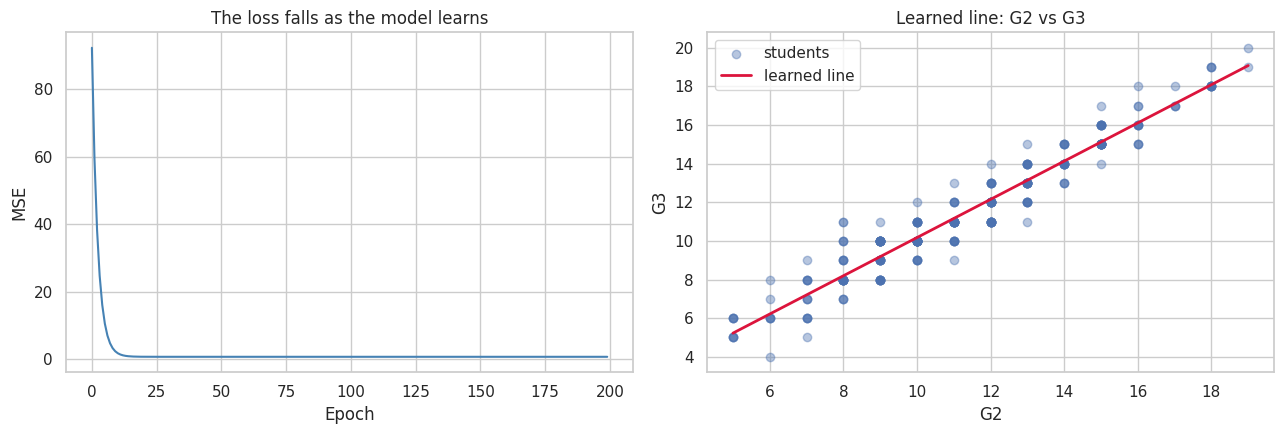

In [258]:
# Cell 92: one feature first (G2 -> G3), so you can see the line learn
x = train["G2"].values
yy = train["G3"].values

x_mean, x_std = x.mean(), x.std()
xs = ((x - x_mean) / x_std).reshape(-1, 1)      # standardised, shape (n, 1)

w, b, hist = gradient_descent(xs, yy, lr=0.1, epochs=200)
print("Learned weight (per 1 std of G2):", w.round(3), "| bias:", round(b, 3))
print("Final MSE:", round(hist[-1], 3), "| RMSE:", round(np.sqrt(hist[-1]), 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist, color="steelblue")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE")
axes[0].set_title("The loss falls as the model learns")

line_x = np.linspace(x.min(), x.max(), 100)
line_y = w[0] * (line_x - x_mean) / x_std + b
axes[1].scatter(x, yy, alpha=0.4, label="students")
axes[1].plot(line_x, line_y, color="crimson", linewidth=2, label="learned line")
axes[1].set_xlabel("G2"); axes[1].set_ylabel("G3"); axes[1].legend()
axes[1].set_title("Learned line: G2 vs G3")
plt.tight_layout()
plt.savefig("scratch_one_feature.png", dpi=150, bbox_inches="tight")
plt.show()

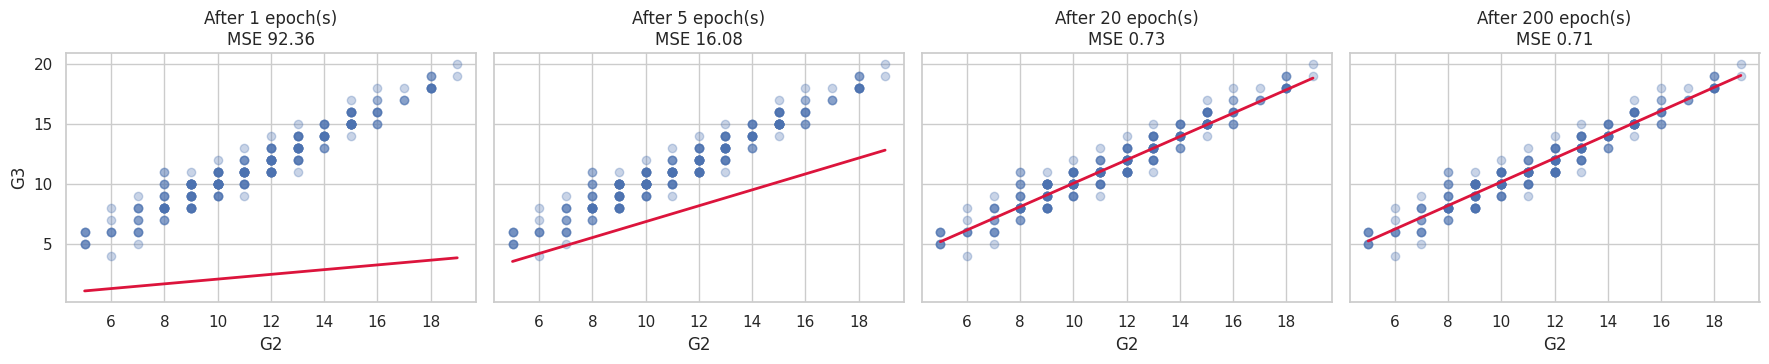

In [259]:
# Cell 93: watch the line learn, snapshots at different epochs
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, ep in zip(axes, [1, 5, 20, 200]):
    w_e, b_e, h_e = gradient_descent(xs, yy, lr=0.1, epochs=ep)
    ax.scatter(x, yy, alpha=0.3)
    ax.plot(line_x, w_e[0] * (line_x - x_mean) / x_std + b_e, color="crimson", linewidth=2)
    ax.set_title(f"After {ep} epoch(s)\nMSE {h_e[-1]:.2f}")
    ax.set_xlabel("G2")
axes[0].set_ylabel("G3")
plt.tight_layout()
plt.savefig("scratch_learning_snapshots.png", dpi=150, bbox_inches="tight")
plt.show()

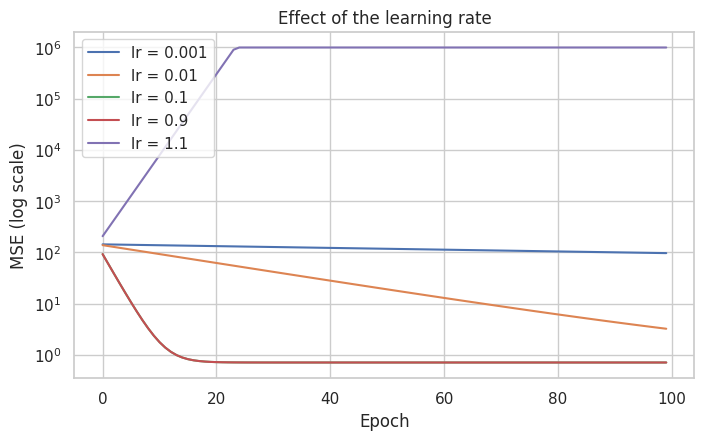

In [260]:
# Cell 94: the learning rate, too small, good, and too big
fig, ax = plt.subplots(figsize=(8, 4.5))
for lr in [0.001, 0.01, 0.1, 0.9, 1.1]:
    _, _, h = gradient_descent(xs, yy, lr=lr, epochs=100)
    h = np.minimum(h, 1e6)         # cap so diverging runs stay on the chart
    ax.plot(h, label=f"lr = {lr}")
ax.set_yscale("log")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (log scale)")
ax.set_title("Effect of the learning rate")
ax.legend()
plt.savefig("scratch_learning_rates.png", dpi=150, bbox_inches="tight")
plt.show()

In [261]:
# Cell 95: turn it into a reusable class (scaling happens INSIDE fit, so no leakage)
class LinearRegressionScratch:
    def __init__(self, lr=0.05, epochs=3000):
        self.lr = lr
        self.epochs = epochs

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.mu = X.mean(axis=0)
        self.sigma = X.std(axis=0)
        self.sigma[self.sigma == 0] = 1.0           # avoid dividing by zero
        Xs = (X - self.mu) / self.sigma
        self.w, self.b, self.history = gradient_descent(Xs, y, self.lr, self.epochs)
        return self

    def predict(self, X):
        Xs = (np.asarray(X, dtype=float) - self.mu) / self.sigma
        return Xs @ self.w + self.b

def cv_rmse_scratch(X, y, **kwargs):
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = []
    for tr, va in kf.split(X):
        m = LinearRegressionScratch(**kwargs).fit(X.iloc[tr], y.iloc[tr])
        scores.append(np.sqrt(mse(y.iloc[va].values, m.predict(X.iloc[va]))))
    return np.array(scores)

In [262]:
# Cell 96: cross-validated results, scratch model vs scikit-learn vs a "dumb" baseline
kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, X in [("early (no G1/G2)", X_early), ("all features", X_all)]:
    scratch = cv_rmse_scratch(X, y, lr=0.05, epochs=3000)
    sk = -cross_val_score(make_pipeline(StandardScaler(), LinearRegression()),
                          X, y, cv=kf, scoring="neg_root_mean_squared_error")
    dummy = -cross_val_score(DummyRegressor(strategy="mean"),
                             X, y, cv=kf, scoring="neg_root_mean_squared_error")
    rows.append({"feature set": name,
                 "baseline (predict the mean)": round(dummy.mean(), 3),
                 "scikit-learn": round(sk.mean(), 3),
                 "from scratch": round(scratch.mean(), 3)})
pd.DataFrame(rows)

,feature set,baseline (predict the mean),scikit-learn,from scratch
0,early (no G1/G2),3.255,3.052,3.052
1,all features,3.255,0.906,0.906


In [263]:
# Cell 97: the normal equation, solving in one step with no loop
def normal_equation(X, y):
    Xb = np.c_[np.ones(len(X)), X]                    # add a bias column
    theta, *_ = np.linalg.lstsq(Xb, y, rcond=None)    # a stable way to solve it
    return theta[1:], theta[0]

model = LinearRegressionScratch(lr=0.05, epochs=3000).fit(X_all, y)
Xs_all = (X_all.values - model.mu) / model.sigma
w_ne, b_ne = normal_equation(Xs_all, y.values)

print("Max difference in weights, gradient descent vs normal equation:",
      np.abs(model.w - w_ne).max().round(5))
print("Bias:", round(model.b, 4), "vs", round(b_ne, 4))
print("Final training MSE:", round(model.history[-1], 4),
      "| normal equation MSE:", round(mse(y.values, Xs_all @ w_ne + b_ne), 4))

Max difference in weights, gradient descent vs normal equation: 0.0
Bias: 11.5474 vs 11.5474
Final training MSE: 0.5674 | normal equation MSE: 0.5674


G2                2.803
G1                0.376
famrel            0.158
Mjob_teacher      0.147
guardian_other   -0.126
health           -0.121
Mjob_other       -0.106
paid             -0.104
Fjob_other        0.104
goout            -0.097
dtype: float64


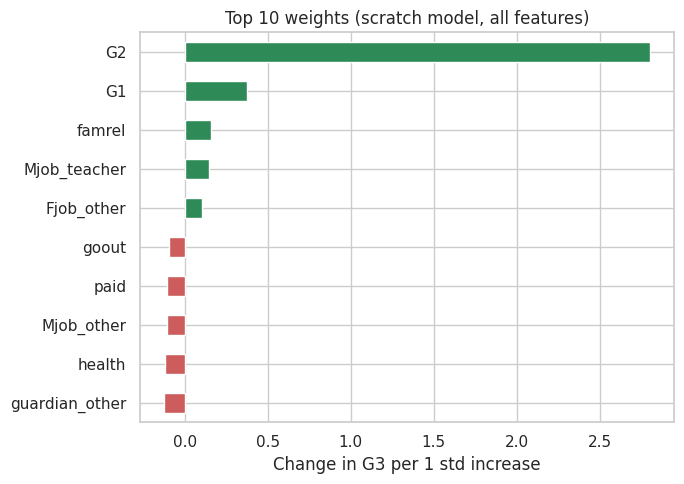

In [264]:
# Cell 98: what did the model learn? (weights are per 1 standard deviation, so comparable)
coefs = pd.Series(model.w, index=X_all.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)
print(top.round(3))

plt.figure(figsize=(7, 5))
top.sort_values().plot(kind="barh", color=np.where(top.sort_values() > 0, "seagreen", "indianred"))
plt.title("Top 10 weights (scratch model, all features)")
plt.xlabel("Change in G3 per 1 std increase")
plt.tight_layout()
plt.savefig("scratch_weights.png", dpi=150, bbox_inches="tight")
plt.show()

In [265]:
%%writefile linreg_scratch.py
# Cell 99: save your model so later days can import it
import numpy as np

def gradient_descent(X, y, lr=0.05, epochs=3000):
    w, b, history = np.zeros(X.shape[1]), 0.0, []
    n = len(y)
    for _ in range(epochs):
        error = X @ w + b - y
        w -= lr * (2 / n) * (X.T @ error)
        b -= lr * (2 / n) * error.sum()
        history.append(np.mean(error ** 2))
    return w, b, history

class LinearRegressionScratch:
    def __init__(self, lr=0.05, epochs=3000):
        self.lr, self.epochs = lr, epochs

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        self.mu, self.sigma = X.mean(axis=0), X.std(axis=0)
        self.sigma[self.sigma == 0] = 1.0
        self.w, self.b, self.history = gradient_descent((X - self.mu) / self.sigma, y, self.lr, self.epochs)
        return self

    def predict(self, X):
        return ((np.asarray(X, float) - self.mu) / self.sigma) @ self.w + self.b

Overwriting linreg_scratch.py


In [266]:
# Cell 100: setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.dummy import DummyRegressor

train = pd.read_csv("train.csv")
y = train["G3"]
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
cv = KFold(n_splits=5, shuffle=True, random_state=42)
print("Train:", train.shape, "| features all:", X_all.shape[1], "| early:", X_early.shape[1])

Train: (285, 42) | features all: 41 | early: 39


In [267]:
# Cell 101: measure multicollinearity with VIF
def vif_table(X):
    Xs = StandardScaler().fit_transform(X)
    out = {}
    for i, c in enumerate(X.columns):
        others = np.delete(Xs, i, axis=1)
        r2 = LinearRegression().fit(others, Xs[:, i]).score(others, Xs[:, i])
        out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out).sort_values(ascending=False)

vif = vif_table(X_all)
print("Highest VIF scores:")
print(vif.head(8).round(2))
print("\nCorrelation between G1 and G2:", round(X_all["G1"].corr(X_all["G2"]), 3))

Highest VIF scores:
G2               7.55
G1               7.45
Fjob_other       5.73
Fjob_services    4.99
Mjob_services    3.19
Mjob_teacher     3.17
Mjob_other       3.08
Medu             2.96
dtype: float64

Correlation between G1 and G2: 0.901


           G1            G2       
         mean    std   mean    std
model                             
Linear  0.371  0.150  2.798  0.171
Ridge   0.988  0.082  1.904  0.072

Linear: correlation between the G1 and G2 weights across resamples:
      G1    G2
G1  1.00 -0.69
G2 -0.69  1.00


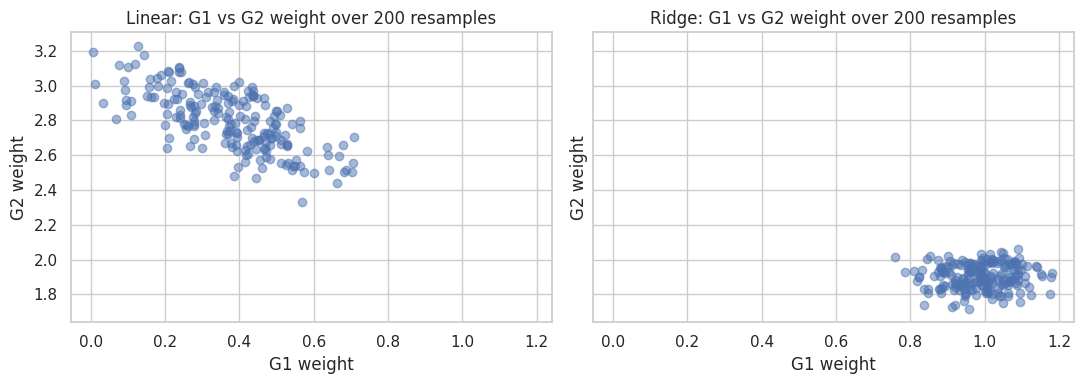

In [268]:
# Cell 102: the instability, shown by refitting on 200 resampled versions of the data
rng = np.random.default_rng(0)
cols = list(X_all.columns)
i1, i2 = cols.index("G1"), cols.index("G2")

rows = []
for _ in range(200):
    idx = rng.integers(0, len(X_all), len(X_all))     # resample with replacement
    Xb, yb = X_all.iloc[idx], y.iloc[idx]
    for name, mdl in [("Linear", LinearRegression()), ("Ridge", Ridge(alpha=30))]:
        coef = make_pipeline(StandardScaler(), mdl).fit(Xb, yb)[-1].coef_
        rows.append({"model": name, "G1": coef[i1], "G2": coef[i2]})
boot = pd.DataFrame(rows)

print(boot.groupby("model")[["G1", "G2"]].agg(["mean", "std"]).round(3))
print("\nLinear: correlation between the G1 and G2 weights across resamples:")
print(boot[boot.model == "Linear"][["G1", "G2"]].corr().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, name in zip(axes, ["Linear", "Ridge"]):
    b = boot[boot.model == name]
    ax.scatter(b["G1"], b["G2"], alpha=0.5)
    ax.set_title(f"{name}: G1 vs G2 weight over 200 resamples")
    ax.set_xlabel("G1 weight"); ax.set_ylabel("G2 weight")
plt.tight_layout()
plt.savefig("weights_stability.png", dpi=150, bbox_inches="tight")
plt.show()

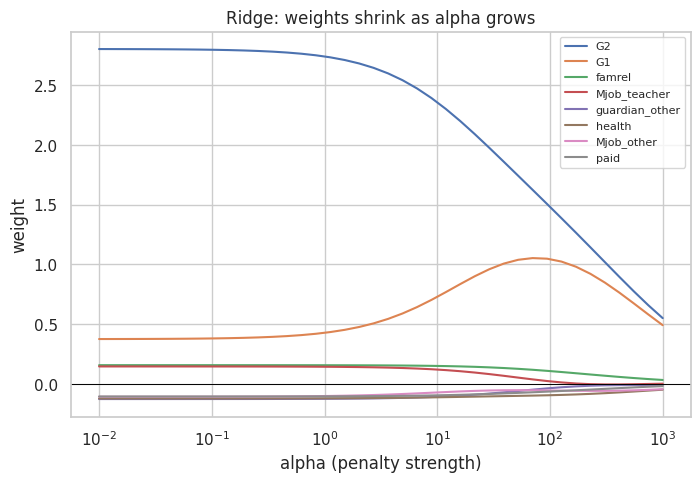

In [269]:
# Cell 103: Ridge coefficient path, what happens as alpha grows
scaler = StandardScaler().fit(X_all)          # exploration on training data only
Xs = scaler.transform(X_all)

alphas = np.logspace(-2, 3, 40)
paths = np.array([Ridge(alpha=a).fit(Xs, y).coef_ for a in alphas])
top = np.argsort(-np.abs(paths[0]))[:8]

plt.figure(figsize=(8, 5))
for j in top:
    plt.plot(alphas, paths[:, j], label=X_all.columns[j])
plt.xscale("log"); plt.axhline(0, color="black", linewidth=0.7)
plt.xlabel("alpha (penalty strength)"); plt.ylabel("weight")
plt.title("Ridge: weights shrink as alpha grows")
plt.legend(fontsize=8)
plt.savefig("ridge_path.png", dpi=150, bbox_inches="tight")
plt.show()

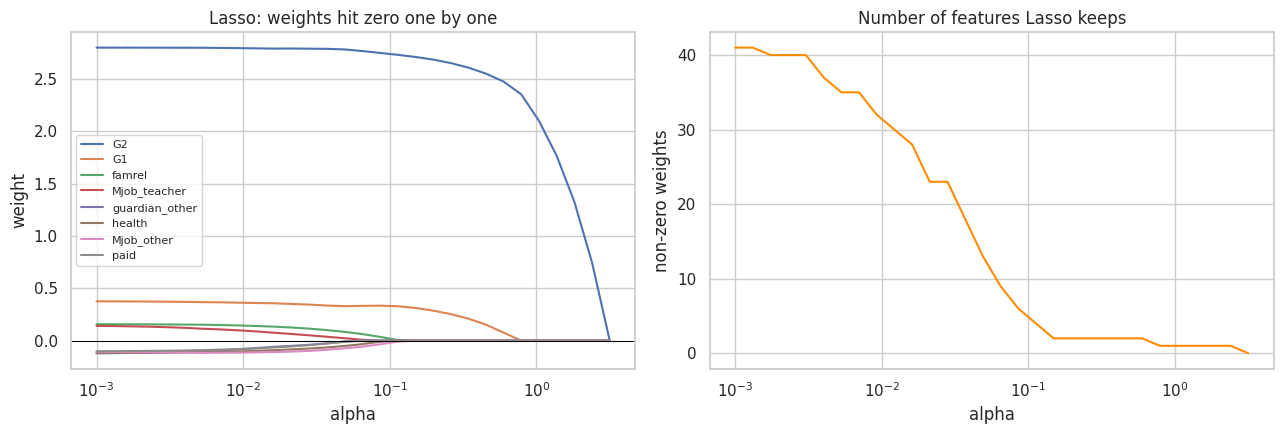

In [270]:
# Cell 104: Lasso path, weights reach exactly zero
lasso_alphas = np.logspace(-3, 0.5, 30)
lpaths, n_nonzero = [], []
for a in lasso_alphas:
    c = Lasso(alpha=a, max_iter=20000).fit(Xs, y).coef_
    lpaths.append(c)
    n_nonzero.append((c != 0).sum())
lpaths = np.array(lpaths)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for j in top:
    axes[0].plot(lasso_alphas, lpaths[:, j], label=X_all.columns[j])
axes[0].set_xscale("log"); axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].set_title("Lasso: weights hit zero one by one")
axes[0].set_xlabel("alpha"); axes[0].set_ylabel("weight"); axes[0].legend(fontsize=8)

axes[1].plot(lasso_alphas, n_nonzero, color="darkorange")
axes[1].set_xscale("log")
axes[1].set_title("Number of features Lasso keeps")
axes[1].set_xlabel("alpha"); axes[1].set_ylabel("non-zero weights")
plt.tight_layout()
plt.savefig("lasso_path.png", dpi=150, bbox_inches="tight")
plt.show()

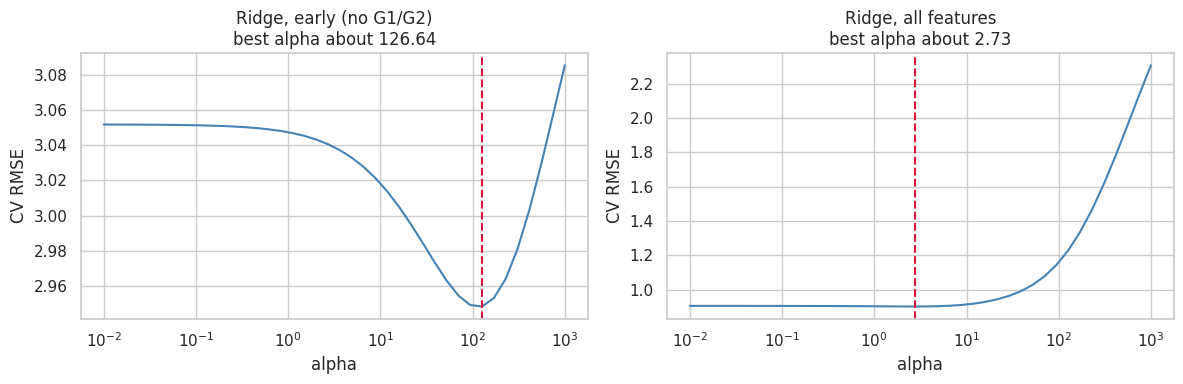

In [271]:
# Cell 105: choosing alpha, CV error across alpha values, for both feature sets
cv_curves = {}
for name, X in [("early (no G1/G2)", X_early), ("all features", X_all)]:
    errs = []
    for a in alphas:
        s = -cross_val_score(make_pipeline(StandardScaler(), Ridge(alpha=a)),
                             X, y, cv=cv, scoring="neg_root_mean_squared_error")
        errs.append(s.mean())
    cv_curves[name] = errs

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, errs) in zip(axes, cv_curves.items()):
    ax.plot(alphas, errs, color="steelblue")
    best = alphas[int(np.argmin(errs))]
    ax.axvline(best, color="crimson", linestyle="--")
    ax.set_xscale("log")
    ax.set_title(f"Ridge, {name}\nbest alpha about {best:.2f}")
    ax.set_xlabel("alpha"); ax.set_ylabel("CV RMSE")
plt.tight_layout()
plt.savefig("ridge_alpha_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [272]:
# Cell 106: fair comparison. RidgeCV and LassoCV pick alpha INSIDE each training fold,
# so the score is not flattered by the tuning.
models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (CV alpha)": make_pipeline(StandardScaler(),
                                      RidgeCV(alphas=np.logspace(-2, 3, 40))),
    "Lasso (CV alpha)": make_pipeline(StandardScaler(),
                                      LassoCV(alphas=np.logspace(-3, 0.5, 30), cv=5, max_iter=20000)),
}

rows = []
for fname, X in [("early (no G1/G2)", X_early), ("all features", X_all)]:
    for mname, m in models.items():
        s = -cross_val_score(m, X, y, cv=cv, scoring="neg_root_mean_squared_error")
        rows.append({"features": fname, "model": mname,
                     "CV RMSE": round(s.mean(), 3), "std": round(s.std(), 3)})
results = pd.DataFrame(rows)
results.pivot(index="model", columns="features", values="CV RMSE")

features,all features,early (no G1/G2)
model,,
Baseline (mean),3.255,3.255
Lasso (CV alpha),0.841,2.951
Linear,0.906,3.052
Ridge (CV alpha),0.903,2.961


In [273]:
# Cell 107: which features does Lasso keep? (fit on all training data)
for fname, X in [("early (no G1/G2)", X_early), ("all features", X_all)]:
    lasso = make_pipeline(StandardScaler(),
                          LassoCV(alphas=np.logspace(-3, 0.5, 30), cv=5, max_iter=20000)).fit(X, y)
    coef = pd.Series(lasso[-1].coef_, index=X.columns)
    kept = coef[coef != 0].sort_values(key=abs, ascending=False)
    print(f"\n{fname}: alpha = {lasso[-1].alpha_:.3f}, kept {len(kept)} of {X.shape[1]} features")
    print(kept.round(3).head(10).to_string())


early (no G1/G2): alpha = 0.149, kept 20 of 39 features
schoolsup       -0.682
failures        -0.576
absences        -0.465
Mjob_services    0.438
Fjob_teacher     0.301
internet         0.276
goout           -0.225
famsup          -0.212
Mjob_health      0.200
Walc            -0.186

all features: alpha = 0.085, kept 6 of 41 features
G2            2.750
G1            0.334
Mjob_other   -0.036
famrel        0.036
health       -0.011
goout        -0.010


In [274]:
# Cell 108: reading the weights in real units (early model, Ridge)
ridge_early = make_pipeline(StandardScaler(),
                            RidgeCV(alphas=np.logspace(-2, 3, 40))).fit(X_early, y)
sc = ridge_early[0]
per_unit = pd.Series(ridge_early[-1].coef_ / sc.scale_, index=X_early.columns)

print("Change in predicted G3 for a 1-unit increase (other features held fixed):")
for c in ["failures", "studytime", "absences", "age", "higher", "Medu", "goout"]:
    print(f"  {c:10s} {per_unit[c]:+.3f}")

Change in predicted G3 for a 1-unit increase (other features held fixed):
  failures   -0.680
  studytime  +0.302
  absences   -0.076
  age        -0.110
  higher     +0.528
  Medu       +0.119
  goout      -0.257


In [275]:
# Cell 109: save the results table, used again on Day 16
results.to_csv("results_linear.csv", index=False)
print(results.to_string(index=False))

        features            model  CV RMSE   std
early (no G1/G2)  Baseline (mean)    3.255 0.125
early (no G1/G2)           Linear    3.052 0.169
early (no G1/G2) Ridge (CV alpha)    2.961 0.086
early (no G1/G2) Lasso (CV alpha)    2.951 0.149
    all features  Baseline (mean)    3.255 0.125
    all features           Linear    0.906 0.079
    all features Ridge (CV alpha)    0.903 0.076
    all features Lasso (CV alpha)    0.841 0.037


In [276]:
# Cell 110: setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             confusion_matrix, precision_score, recall_score, accuracy_score)

sns.set_theme(style="whitegrid")
train = pd.read_csv("train.csv")
y = train["G3"]
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
cv = KFold(n_splits=5, shuffle=True, random_state=42)
print("Train:", train.shape, "| lowest G3 in the data:", y.min())

Train: (285, 42) | lowest G3 in the data: 4


In [277]:
# Cell 111: the metrics written by hand, then checked against scikit-learn
def mse_(y, p):  return np.mean((y - p) ** 2)
def rmse_(y, p): return np.sqrt(mse_(y, p))
def mae_(y, p):  return np.mean(np.abs(y - p))
def r2_(y, p):   return 1 - np.sum((y - p) ** 2) / np.sum((y - np.mean(y)) ** 2)
def mape_(y, p): return np.mean(np.abs(y - p) / np.abs(y)) * 100

y_demo = np.array([10, 12, 11, 13, 12], dtype=float)
p_demo = np.array([11, 11, 12, 15, 10], dtype=float)

print(f"{'metric':8s}{'by hand':>10s}{'sklearn':>10s}")
print(f"{'MSE':8s}{mse_(y_demo, p_demo):10.4f}{mean_squared_error(y_demo, p_demo):10.4f}")
print(f"{'MAE':8s}{mae_(y_demo, p_demo):10.4f}{mean_absolute_error(y_demo, p_demo):10.4f}")
print(f"{'R2':8s}{r2_(y_demo, p_demo):10.4f}{r2_score(y_demo, p_demo):10.4f}")
print(f"{'RMSE':8s}{rmse_(y_demo, p_demo):10.4f}")

metric     by hand   sklearn
MSE         2.2000    2.2000
MAE         1.4000    1.4000
R2         -1.1154   -1.1154
RMSE        1.4832


In [278]:
# Cell 112: RMSE punishes big misses, MAE does not
actual = np.array([10, 12, 11, 13, 12], dtype=float)
model_a = np.array([11, 13, 12, 14, 13], dtype=float)    # misses by 1 every time
model_b = np.array([10, 12, 11, 13, 17], dtype=float)    # perfect four times, one miss of 5

for name, p in [("Model A (steady small misses)", model_a), ("Model B (one big miss)", model_b)]:
    print(f"{name:32s} MAE = {mae_(actual, p):.2f} | RMSE = {rmse_(actual, p):.2f}")

Model A (steady small misses)    MAE = 1.00 | RMSE = 1.00
Model B (one big miss)           MAE = 1.00 | RMSE = 2.24


In [279]:
# Cell 113: cross-validated predictions for each model and feature set
models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 40))),
}
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

preds = {}
for fname, X in feature_sets.items():
    for mname, m in models.items():
        preds[(fname, mname)] = cross_val_predict(m, X, y, cv=cv)

rows = []
for (fname, mname), p in preds.items():
    base_mae = mae_(y.values, preds[(fname, "Baseline (mean)")])
    rows.append({"features": fname, "model": mname,
                 "MAE": round(mae_(y.values, p), 3),
                 "RMSE": round(rmse_(y.values, p), 3),
                 "R2": round(r2_(y.values, p), 3),
                 "scaled MAE": round(mae_(y.values, p) / base_mae, 3)})
metrics = pd.DataFrame(rows)
metrics

,features,model,MAE,RMSE,R2,scaled MAE
0,early (no G1/G2),Baseline (mean),2.655,3.257,-0.003,1.000
1,early (no G1/G2),Linear,2.439,3.057,0.117,0.919
2,early (no G1/G2),Ridge,2.398,2.962,0.170,0.903
3,all features,Baseline (mean),2.655,3.257,-0.003,1.000
4,all features,Linear,0.743,0.909,0.922,0.280
5,all features,Ridge,0.739,0.906,0.922,0.278


In [280]:
# Cell 114: why MAPE is a poor choice here
y_zero = np.array([0, 8, 12, 15], dtype=float)
p_zero = np.array([1, 9, 11, 14], dtype=float)           # every prediction misses by exactly 1
with np.errstate(divide="ignore"):
    print("Percentage errors when one student scored 0:", np.abs(y_zero - p_zero) / np.abs(y_zero))

print("\nThe same 1-point miss, at different grades:")
for g in [5, 8, 12, 18]:
    print(f"  grade {g:2d}: {100 / g:5.1f}% error")

best = preds[("all features", "Ridge")]
print("\nOn our cleaned data (Ridge, all features):")
print(f"  MAE  = {mae_(y.values, best):.2f} grade points")
print(f"  MAPE = {mape_(y.values, best):.1f}%  <- pulled up by the low-grade students")

Percentage errors when one student scored 0: [       inf 0.125      0.08333333 0.06666667]

The same 1-point miss, at different grades:
  grade  5:  20.0% error
  grade  8:  12.5% error
  grade 12:   8.3% error
  grade 18:   5.6% error

On our cleaned data (Ridge, all features):
  MAE  = 0.74 grade points
  MAPE = 7.2%  <- pulled up by the low-grade students


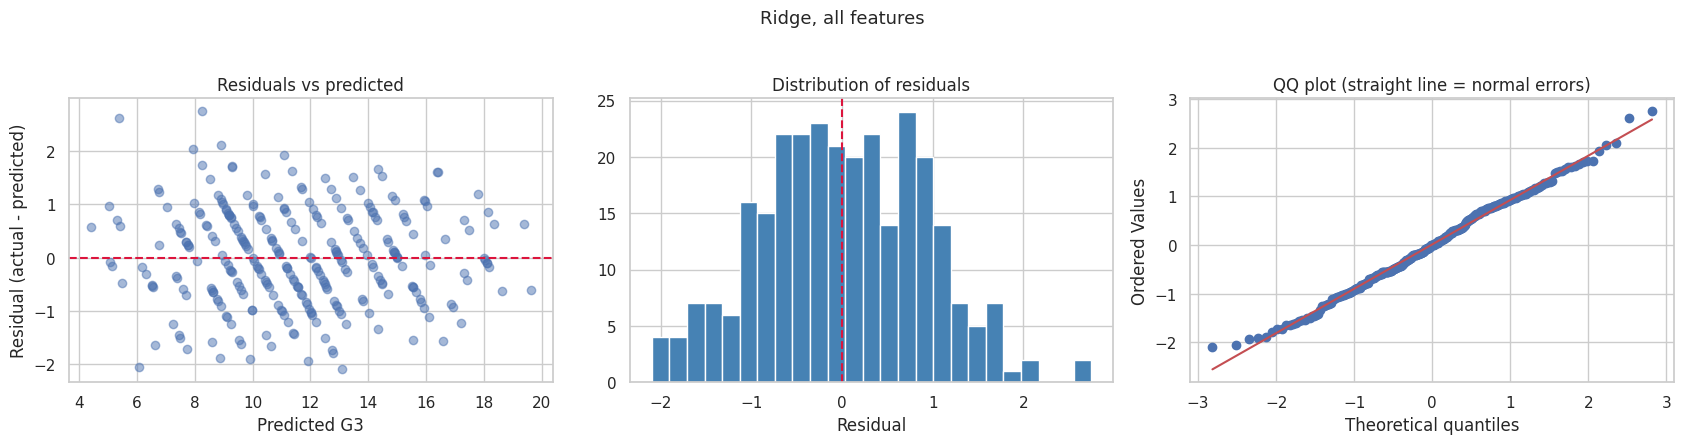

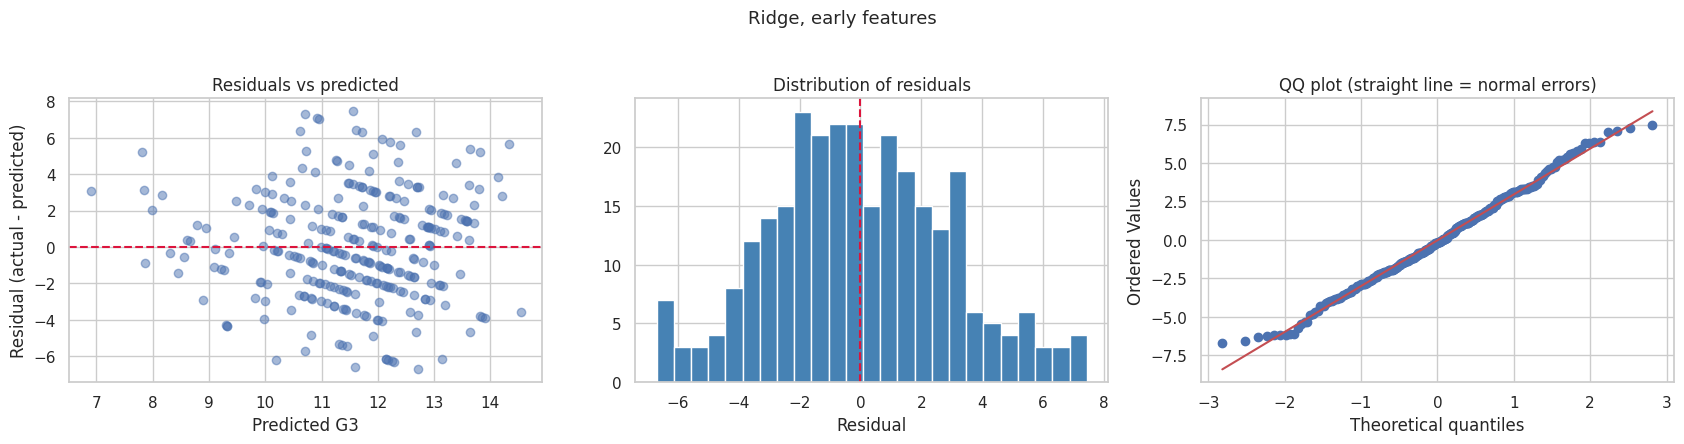

In [281]:
# Cell 115: residual diagnostics, three plots per model
def residual_plots(p, title, fname):
    resid = y.values - p
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))

    axes[0].scatter(p, resid, alpha=0.5)
    axes[0].axhline(0, color="crimson", linestyle="--")
    axes[0].set_xlabel("Predicted G3"); axes[0].set_ylabel("Residual (actual - predicted)")
    axes[0].set_title("Residuals vs predicted")

    axes[1].hist(resid, bins=25, color="steelblue", edgecolor="white")
    axes[1].axvline(0, color="crimson", linestyle="--")
    axes[1].set_xlabel("Residual"); axes[1].set_title("Distribution of residuals")

    stats.probplot(resid, dist="norm", plot=axes[2])
    axes[2].set_title("QQ plot (straight line = normal errors)")

    fig.suptitle(title, y=1.03, fontsize=13)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()

residual_plots(preds[("all features", "Ridge")], "Ridge, all features", "residuals_all.png")
residual_plots(preds[("early (no G1/G2)", "Ridge")], "Ridge, early features", "residuals_early.png")

In [282]:
# Cell 116: where does the model fail? Error by grade band
bands = pd.cut(y, bins=[0, 7, 9, 12, 15, 20],
               labels=["4-7", "8-9", "10-12", "13-15", "16-20"])

def band_table(p):
    d = pd.DataFrame({"band": bands, "resid": y.values - p})
    return d.groupby("band", observed=True)["resid"].agg(
        n="count",
        mean_resid="mean",
        MAE=lambda r: r.abs().mean()).round(2)

print("ALL FEATURES (Ridge):")
print(band_table(preds[("all features", "Ridge")]))
print("\nEARLY FEATURES (Ridge):")
print(band_table(preds[("early (no G1/G2)", "Ridge")]))

ALL FEATURES (Ridge):
         n  mean_resid   MAE
band                        
4-7     25       -0.59  0.84
8-9     48       -0.16  0.75
10-12  109        0.01  0.77
13-15   69        0.17  0.64
16-20   34        0.41  0.73

EARLY FEATURES (Ridge):
         n  mean_resid   MAE
band                        
4-7     25       -4.78  4.78
8-9     48       -2.43  2.46
10-12  109       -0.66  1.33
13-15   69        1.99  1.99
16-20   34        4.81  4.81


In [283]:
# Cell 117: do errors differ across groups? (an early look at fairness, done properly in Phase 5)
groups = {
    "sex (0=F, 1=M)": X_all["sex"],
    "school (0=GP, 1=MS)": X_all["school"],
    "address (0=rural, 1=urban)": X_all["address"],
    "has past failures": (X_all["failures"] > 0).astype(int),
    "wants higher education": X_all["higher"],
}

rows = []
for gname, col in groups.items():
    for val in sorted(col.unique()):
        mask = (col == val).values
        for fname in ["early (no G1/G2)", "all features"]:
            resid = y.values[mask] - preds[(fname, "Ridge")][mask]
            rows.append({"group": gname, "value": val, "n": mask.sum(), "features": fname,
                         "mean residual": round(resid.mean(), 2),
                         "MAE": round(np.abs(resid).mean(), 2)})
group_table = pd.DataFrame(rows)
group_table.pivot_table(index=["group", "value", "n"], columns="features",
                        values=["mean residual", "MAE"])

MAE                   \
features                             all features early (no G1/G2)   
group                      value n                                   
address (0=rural, 1=urban) 0     63          0.70             2.38   
                           1     222         0.75             2.40   
has past failures          0     233         0.74             2.45   
                           1     52          0.73             2.16   
school (0=GP, 1=MS)        0     252         0.73             2.42   
                           1     33          0.80             2.24   
sex (0=F, 1=M)             0     148         0.77             2.37   
                           1     137         0.71             2.43   
wants higher education     0     12          0.61             1.65   
                           1     273         0.74             2.43   

                                     mean residual                   
features                              all features early (no G1/G2)  
group                      value n                                   
address (0=rural, 1=urban) 0     63          -0.03            -0.13  
                           1     222          0.03             0.01  
has past failures          0     233          0.02             0.09  
                           1     52          -0.02            -0.52  
school (0=GP, 1=MS)        0     252          0.01             0.00  
                           1     33           0.02            -0.20  
sex (0=F, 1=M)             0     148          0.00            -0.13  
                           1     137          0.02             0.09  
wants higher education     0     12           0.12            -0.20  
                           1     273          0.01            -0.02

In [284]:
# Cell 118: at-risk detection, flag students predicted to score below 10
y_fail = (y < 10).astype(int).values
print(f"Students who actually scored below 10: {y_fail.sum()} of {len(y)} ({y_fail.mean():.1%})")

rows = []
for fname in ["early (no G1/G2)", "all features"]:
    flag = (preds[(fname, "Ridge")] < 10).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_fail, flag).ravel()
    rows.append({"features": fname, "flagged": flag.sum(),
                 "caught (TP)": tp, "missed (FN)": fn, "false alarms (FP)": fp,
                 "accuracy": round(accuracy_score(y_fail, flag), 3),
                 "precision": round(precision_score(y_fail, flag, zero_division=0), 3),
                 "recall": round(recall_score(y_fail, flag, zero_division=0), 3)})

nobody = np.zeros_like(y_fail)
rows.append({"features": "flag nobody", "flagged": 0, "caught (TP)": 0,
             "missed (FN)": y_fail.sum(), "false alarms (FP)": 0,
             "accuracy": round(accuracy_score(y_fail, nobody), 3),
             "precision": np.nan, "recall": 0.0})
pd.DataFrame(rows)

Students who actually scored below 10: 73 of 285 (25.6%)


,features,flagged,caught (TP),missed (FN),false alarms (FP),accuracy,precision,recall
0,early (no G1/G2),34,20,53,14,0.765,0.588,0.274
1,all features,102,71,2,31,0.884,0.696,0.973
2,flag nobody,0,0,73,0,0.744,NaN,0.000


In [285]:
# Cell 119: save the results for the final report
metrics.to_csv("metrics_cv.csv", index=False)

out = X_all.copy()
out["G3"] = y
for (fname, mname), p in preds.items():
    out[f"pred_{fname.split()[0]}_{mname.split()[0]}"] = p
out.to_csv("cv_predictions.csv", index=False)
print("Saved metrics_cv.csv and cv_predictions.csv")
print(metrics.to_string(index=False))

Saved metrics_cv.csv and cv_predictions.csv
        features           model   MAE  RMSE     R2  scaled MAE
early (no G1/G2) Baseline (mean) 2.655 3.257 -0.003       1.000
early (no G1/G2)          Linear 2.439 3.057  0.117       0.919
early (no G1/G2)           Ridge 2.398 2.962  0.170       0.903
    all features Baseline (mean) 2.655 3.257 -0.003       1.000
    all features          Linear 0.743 0.909  0.922       0.280
    all features           Ridge 0.739 0.906  0.922       0.278


In [286]:
# Cell 120: setup
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (KFold, cross_val_score, learning_curve,
                                     validation_curve, GridSearchCV)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

sns.set_theme(style="whitegrid")
train = pd.read_csv("train.csv")
y = train["G3"]
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = "neg_root_mean_squared_error"
base_rmse = -cross_val_score(DummyRegressor(), X_all, y, cv=cv, scoring=scoring).mean()
print("Train:", train.shape, "| baseline CV RMSE (predict the mean):", round(base_rmse, 3))

Train: (285, 42) | baseline CV RMSE (predict the mean): 3.255


degree 1: train RMSE 0.915 | other students RMSE 0.860
degree 3: train RMSE 0.877 | other students RMSE 0.899
degree 9: train RMSE 0.673 | other students RMSE 1.120


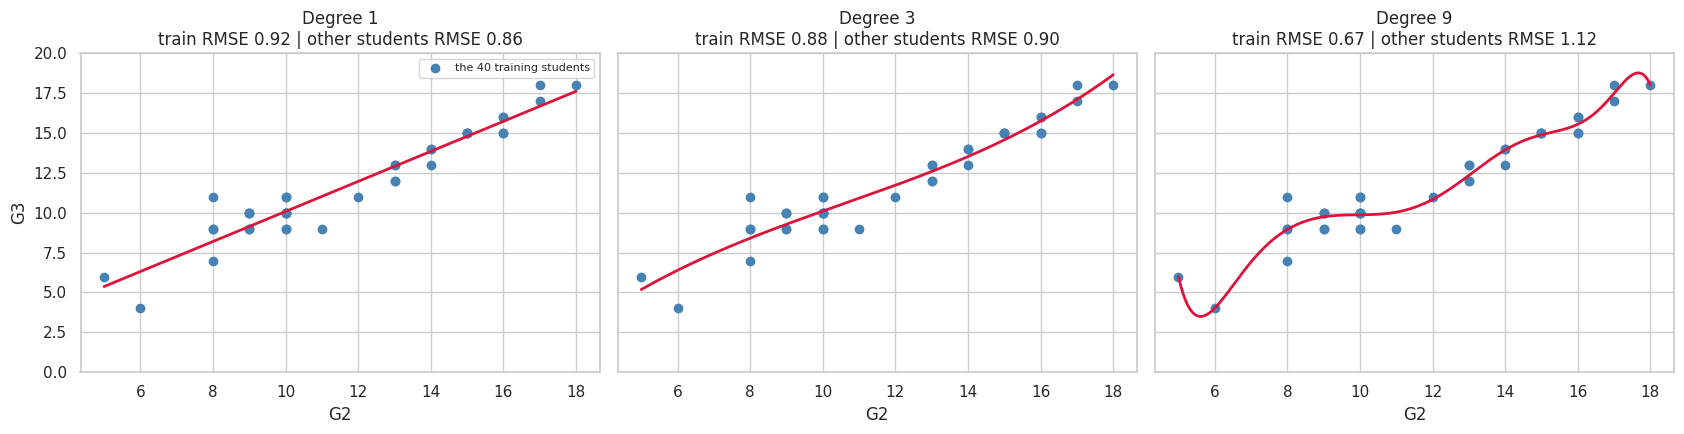

In [287]:
# Cell 121: underfitting and overfitting you can see (G2 -> G3, only 40 students to learn from)
rng = np.random.default_rng(1)
idx = rng.choice(len(train), 40, replace=False)
small = train.iloc[idx]
rest = train.drop(train.index[idx])

xs = ((small["G2"] - 10) / 5).values.reshape(-1, 1)     # scaled to keep powers tame
ys = small["G3"].values
lo, hi = xs.min(), xs.max()

xr_all = ((rest["G2"] - 10) / 5).values.reshape(-1, 1)
inside = ((xr_all >= lo) & (xr_all <= hi)).ravel()      # judge only where the model has seen data
xr, yr = xr_all[inside], rest["G2"].index[inside]
yr = rest.loc[yr, "G3"].values

grid = np.linspace(lo, hi, 200).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, d in zip(axes, [1, 3, 9]):
    m = make_pipeline(PolynomialFeatures(d), LinearRegression()).fit(xs, ys)
    tr_e = np.sqrt(mean_squared_error(ys, m.predict(xs)))
    te_e = np.sqrt(mean_squared_error(yr, m.predict(xr)))
    ax.scatter(xs * 5 + 10, ys, color="steelblue", label="the 40 training students")
    ax.plot(grid * 5 + 10, m.predict(grid), color="crimson", linewidth=2)
    ax.set_title(f"Degree {d}\ntrain RMSE {tr_e:.2f} | other students RMSE {te_e:.2f}")
    ax.set_xlabel("G2"); ax.set_ylim(0, 20)
    print(f"degree {d}: train RMSE {tr_e:.3f} | other students RMSE {te_e:.3f}")
axes[0].set_ylabel("G3"); axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("underfit_overfit.png", dpi=150, bbox_inches="tight")
plt.show()

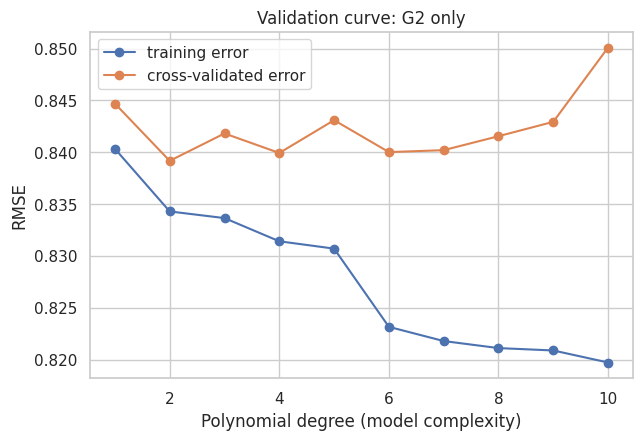

Best degree by CV: 2 | CV RMSE: 0.839


In [288]:
# Cell 122: validation curve for model complexity (polynomial degree on G2, all training students)
degrees = np.arange(1, 11)
Xg = ((train[["G2"]] - 10) / 5).values
poly = make_pipeline(PolynomialFeatures(), LinearRegression())
tr, va = validation_curve(poly, Xg, y, param_name="polynomialfeatures__degree",
                          param_range=degrees, cv=cv, scoring=scoring)
tr, va = -tr.mean(axis=1), -va.mean(axis=1)

plt.figure(figsize=(7, 4.5))
plt.plot(degrees, tr, "o-", label="training error")
plt.plot(degrees, va, "o-", label="cross-validated error")
plt.xlabel("Polynomial degree (model complexity)"); plt.ylabel("RMSE")
plt.title("Validation curve: G2 only")
plt.legend()
plt.savefig("validation_poly.png", dpi=150, bbox_inches="tight")
plt.show()
print("Best degree by CV:", degrees[int(np.argmin(va))], "| CV RMSE:", va.min().round(3))

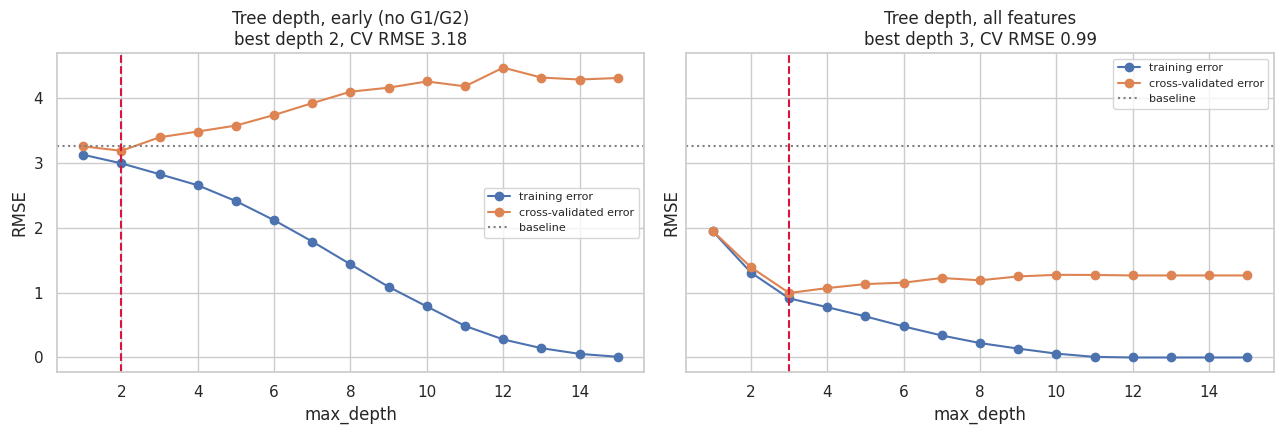

{'early (no G1/G2)': np.int64(2), 'all features': np.int64(3)}


In [289]:
# Cell 123: validation curve for a decision tree, depth is the complexity knob
depths = np.arange(1, 16)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
best_depth = {}
for ax, (name, X) in zip(axes, feature_sets.items()):
    tr, va = validation_curve(DecisionTreeRegressor(random_state=42), X, y,
                              param_name="max_depth", param_range=depths,
                              cv=cv, scoring=scoring)
    tr, va = -tr.mean(axis=1), -va.mean(axis=1)
    best_depth[name] = depths[int(np.argmin(va))]
    ax.plot(depths, tr, "o-", label="training error")
    ax.plot(depths, va, "o-", label="cross-validated error")
    ax.axhline(base_rmse, color="gray", linestyle=":", label="baseline")
    ax.axvline(best_depth[name], color="crimson", linestyle="--")
    ax.set_title(f"Tree depth, {name}\nbest depth {best_depth[name]}, CV RMSE {va.min():.2f}")
    ax.set_xlabel("max_depth"); ax.set_ylabel("RMSE"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("validation_tree.png", dpi=150, bbox_inches="tight")
plt.show()
print(best_depth)

Ridge, early features                      final train 2.58 | final CV 3.02 | gap 0.44
Ridge, all features                        final train 0.76 | final CV 0.91 | gap 0.15
Deep tree (no limit), all features         final train 0.00 | final CV 1.26 | gap 1.26
Shallow tree (depth 3), all features       final train 0.91 | final CV 0.99 | gap 0.08


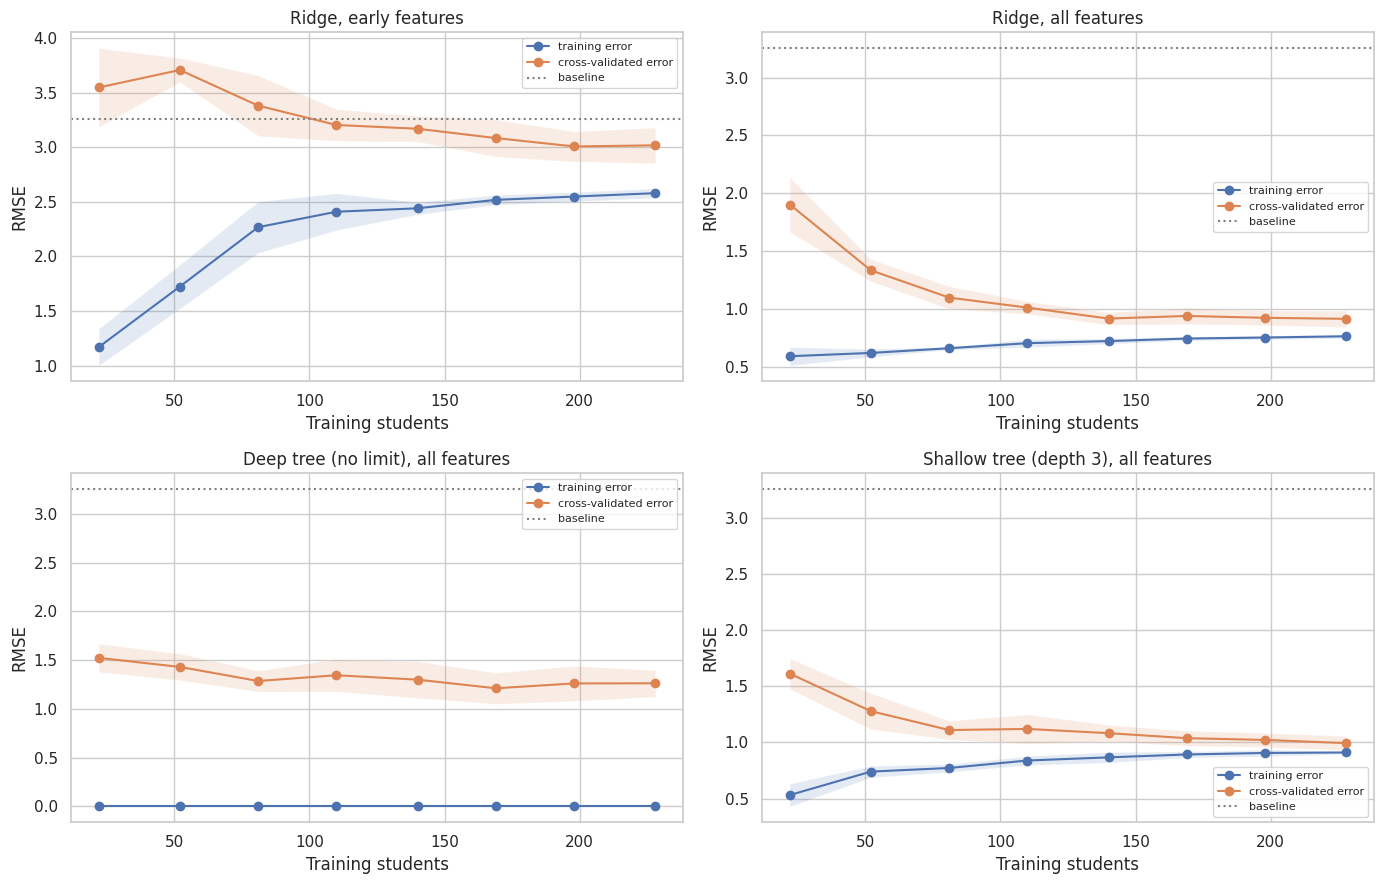

In [290]:
# Cell 124: learning curves, would more students help?
def plot_lc(ax, model, X, title):
    sizes, tr, va = learning_curve(model, X, y, cv=cv, scoring=scoring,
                                   train_sizes=np.linspace(0.1, 1.0, 8),
                                   shuffle=True, random_state=42)
    tr, va = -tr, -va
    ax.plot(sizes, tr.mean(axis=1), "o-", label="training error")
    ax.fill_between(sizes, tr.mean(axis=1) - tr.std(axis=1), tr.mean(axis=1) + tr.std(axis=1), alpha=0.15)
    ax.plot(sizes, va.mean(axis=1), "o-", label="cross-validated error")
    ax.fill_between(sizes, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), alpha=0.15)
    ax.axhline(base_rmse, color="gray", linestyle=":", label="baseline")
    ax.set_title(title); ax.set_xlabel("Training students"); ax.set_ylabel("RMSE")
    ax.legend(fontsize=8)
    print(f"{title:42s} final train {tr.mean(axis=1)[-1]:.2f} | final CV {va.mean(axis=1)[-1]:.2f}"
          f" | gap {va.mean(axis=1)[-1] - tr.mean(axis=1)[-1]:.2f}")

ridge = make_pipeline(StandardScaler(), Ridge(alpha=10))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_lc(axes[0, 0], ridge, X_early, "Ridge, early features")
plot_lc(axes[0, 1], ridge, X_all, "Ridge, all features")
plot_lc(axes[1, 0], DecisionTreeRegressor(random_state=42), X_all, "Deep tree (no limit), all features")
plot_lc(axes[1, 1], DecisionTreeRegressor(max_depth=3, random_state=42), X_all, "Shallow tree (depth 3), all features")
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [291]:
# Cell 125: GridSearchCV for the decision tree
tree_grid = {"max_depth": [2, 3, 4, 5, 6, 8],
             "min_samples_leaf": [1, 5, 10, 20]}
tuned = {}

for name, X in feature_sets.items():
    gs = GridSearchCV(DecisionTreeRegressor(random_state=42), tree_grid,
                      cv=cv, scoring=scoring, n_jobs=-1).fit(X, y)
    tuned[("Tree", name)] = gs
    print(f"\n{name}: best {gs.best_params_} | CV RMSE {-gs.best_score_:.3f}")
    res = pd.DataFrame(gs.cv_results_)
    res["RMSE"] = -res["mean_test_score"]
    print(res.sort_values("RMSE")[["param_max_depth", "param_min_samples_leaf", "RMSE"]]
          .head(5).round(3).to_string(index=False))


early (no G1/G2): best {'max_depth': 2, 'min_samples_leaf': 5} | CV RMSE 3.175
 param_max_depth  param_min_samples_leaf  RMSE
               2                       5 3.175
               2                       1 3.183
               2                      20 3.221
               3                      20 3.237
               4                      20 3.240

all features: best {'max_depth': 5, 'min_samples_leaf': 10} | CV RMSE 0.914
 param_max_depth  param_min_samples_leaf  RMSE
               5                      10 0.914
               6                      10 0.916
               8                      10 0.916
               4                      10 0.922
               4                       5 0.987


In [292]:
# Cell 126: GridSearchCV for Ridge (a pipeline, so the parameter is named step__parameter)
ridge_pipe = make_pipeline(StandardScaler(), Ridge())
ridge_grid = {"ridge__alpha": np.logspace(-2, 3, 20)}

for name, X in feature_sets.items():
    gs = GridSearchCV(ridge_pipe, ridge_grid, cv=cv, scoring=scoring, n_jobs=-1).fit(X, y)
    tuned[("Ridge", name)] = gs
    print(f"{name}: best alpha {gs.best_params_['ridge__alpha']:.2f} | CV RMSE {-gs.best_score_:.3f}")

early (no G1/G2): best alpha 88.59 | CV RMSE 2.950
all features: best alpha 2.34 | CV RMSE 0.902


In [293]:
# Cell 127: nested CV, an honest estimate of "tune, then predict new students"
outer = KFold(n_splits=5, shuffle=True, random_state=7)     # different folds from the inner loop
estimators = {"Tree": (DecisionTreeRegressor(random_state=42), tree_grid),
              "Ridge": (ridge_pipe, ridge_grid)}

rows = []
for (mname, fname), gs in tuned.items():
    est, grid_ = estimators[mname]
    nested = -cross_val_score(GridSearchCV(est, grid_, cv=cv, scoring=scoring, n_jobs=-1),
                              feature_sets[fname], y, cv=outer, scoring=scoring)
    rows.append({"model": mname, "features": fname,
                 "best CV RMSE (optimistic)": round(-gs.best_score_, 3),
                 "nested CV RMSE (honest)": round(nested.mean(), 3),
                 "std": round(nested.std(), 3)})
nested_table = pd.DataFrame(rows).sort_values(["features", "model"])
nested_table

,model,features,best CV RMSE (optimistic),nested CV RMSE (honest),std
3,Ridge,all features,0.902,0.896,0.068
1,Tree,all features,0.914,0.951,0.084
2,Ridge,early (no G1/G2),2.950,2.948,0.283
0,Tree,early (no G1/G2),3.175,3.191,0.328


In [294]:
# Cell 128: how much did tuning actually buy us?
default_rows = []
for fname, X in feature_sets.items():
    for mname, est in [("Tree", DecisionTreeRegressor(random_state=42)),
                       ("Ridge", make_pipeline(StandardScaler(), Ridge()))]:
        s = -cross_val_score(est, X, y, cv=outer, scoring=scoring).mean()
        default_rows.append({"model": mname, "features": fname, "default settings RMSE": round(s, 3)})
comparison = pd.DataFrame(default_rows).merge(nested_table, on=["model", "features"])
comparison["gain from tuning"] = (comparison["default settings RMSE"]
                                  - comparison["nested CV RMSE (honest)"]).round(3)
comparison[["model", "features", "default settings RMSE", "nested CV RMSE (honest)", "gain from tuning"]]

,model,features,default settings RMSE,nested CV RMSE (honest),gain from tuning
0,Tree,early (no G1/G2),4.412,3.191,1.221
1,Ridge,early (no G1/G2),3.077,2.948,0.129
2,Tree,all features,1.191,0.951,0.240
3,Ridge,all features,0.889,0.896,-0.007


In [295]:
# Cell 129: save the tuned settings for later days
def clean(d):
    return {k: (float(v) if isinstance(v, np.floating) else int(v) if isinstance(v, np.integer) else v)
            for k, v in d.items()}

best = {f"{m} | {f}": clean(gs.best_params_) for (m, f), gs in tuned.items()}
with open("best_params_day14.json", "w") as f:
    json.dump(best, f, indent=2)

nested_table.to_csv("tuning_results.csv", index=False)
print(json.dumps(best, indent=2))

{
  "Tree | early (no G1/G2)": {
    "max_depth": 2,
    "min_samples_leaf": 5
  },
  "Tree | all features": {
    "max_depth": 5,
    "min_samples_leaf": 10
  },
  "Ridge | early (no G1/G2)": {
    "ridge__alpha": 88.58667904100822
  },
  "Ridge | all features": {
    "ridge__alpha": 2.3357214690901213
  }
}


In [296]:
# Cell 130: setup and the new target
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
train = pd.read_csv("train.csv")
y_grade = train["G3"]
y = (y_grade < 10).astype(int)
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # keeps the at-risk share in every fold
print("Training students:", len(y))
print("At risk (G3 < 10):", y.sum(), f"({y.mean():.1%})")
print("Not at risk      :", (1 - y).sum(), f"({1 - y.mean():.1%})")

Training students: 285
At risk (G3 < 10): 73 (25.6%)
Not at risk      : 212 (74.4%)


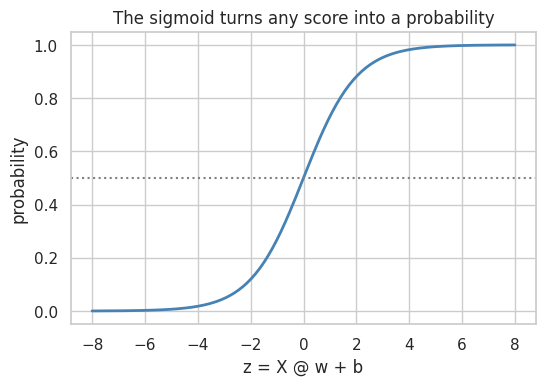

From scratch :  w = [-4.768]  b = -3.583
scikit-learn :  w = [-5.534]  b = [-4.156]


In [297]:
# Cell 131: the sigmoid, and logistic regression from scratch (one feature: G2)
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

zs = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 3.8))
plt.plot(zs, sigmoid(zs), color="steelblue", linewidth=2)
plt.axhline(0.5, color="gray", linestyle=":")
plt.xlabel("z = X @ w + b"); plt.ylabel("probability")
plt.title("The sigmoid turns any score into a probability")
plt.savefig("sigmoid.png", dpi=150, bbox_inches="tight")
plt.show()

x = ((train["G2"] - train["G2"].mean()) / train["G2"].std()).values.reshape(-1, 1)
yy = y.values
w, b = np.zeros(1), 0.0
for _ in range(3000):
    p = sigmoid(x @ w + b)
    w -= 0.1 * (x.T @ (p - yy)) / len(yy)      # same shape as Day 11, but with (p - y)
    b -= 0.1 * (p - yy).mean()

sk = LogisticRegression(C=1e6, max_iter=5000).fit(x, yy)     # almost no regularisation
print("From scratch :  w =", w.round(3), " b =", round(b, 3))
print("scikit-learn :  w =", sk.coef_[0].round(3), " b =", sk.intercept_.round(3))

In [298]:
# Cell 132: the "do nothing" baseline
dummy_pred = cross_val_predict(DummyClassifier(strategy="most_frequent"), X_all, y, cv=skf)
print("Flag nobody  -> accuracy:", round(accuracy_score(y, dummy_pred), 3),
      "| recall:", recall_score(y, dummy_pred),
      "| students caught:", int(((dummy_pred == 1) & (y == 1)).sum()))
print("Accuracy looks respectable, yet this 'model' helps no one.")

Flag nobody  -> accuracy: 0.744 | recall: 0.0 | students caught: 0
Accuracy looks respectable, yet this 'model' helps no one.


In [299]:
# Cell 133: logistic regression, cross-validated probabilities for both feature sets
def make_lr(**kwargs):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, **kwargs))

proba = {}
for fname, X in feature_sets.items():
    proba[fname] = cross_val_predict(make_lr(), X, y, cv=skf, method="predict_proba")[:, 1]

def metrics_at(p, t=0.5):
    flag = (p >= t).astype(int)
    return {"flagged": int(flag.sum()),
            "accuracy": round(accuracy_score(y, flag), 3),
            "precision": round(precision_score(y, flag, zero_division=0), 3),
            "recall": round(recall_score(y, flag, zero_division=0), 3),
            "F1": round(f1_score(y, flag, zero_division=0), 3),
            "ROC AUC": round(roc_auc_score(y, p), 3),
            "PR AUC": round(average_precision_score(y, p), 3)}

results = pd.DataFrame({fname: metrics_at(p) for fname, p in proba.items()}).T
results

,flagged,accuracy,precision,recall,F1,ROC AUC,PR AUC
early (no G1/G2),45.0,0.740,0.489,0.301,0.373,0.662,0.412
all features,65.0,0.881,0.800,0.712,0.754,0.954,0.878


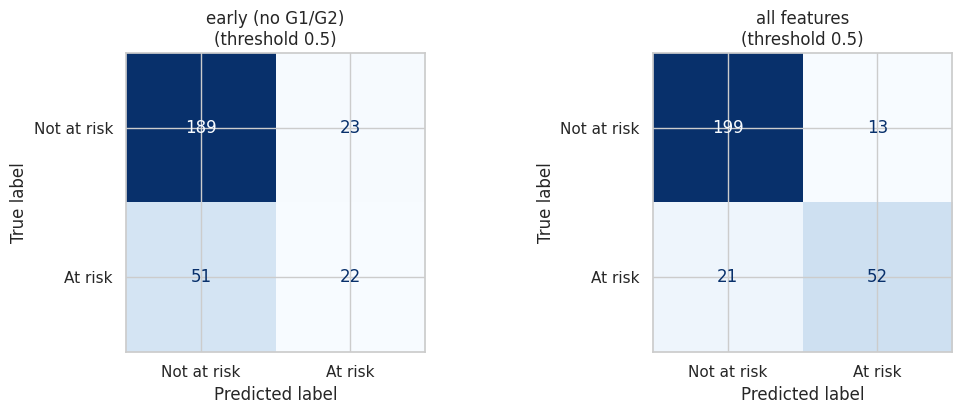

In [300]:
# Cell 134: confusion matrices at the default 0.5 threshold
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (fname, p) in zip(axes, proba.items()):
    ConfusionMatrixDisplay.from_predictions(y, (p >= 0.5).astype(int), ax=ax,
                                            display_labels=["Not at risk", "At risk"],
                                            cmap="Blues", colorbar=False)
    ax.set_title(f"{fname}\n(threshold 0.5)")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

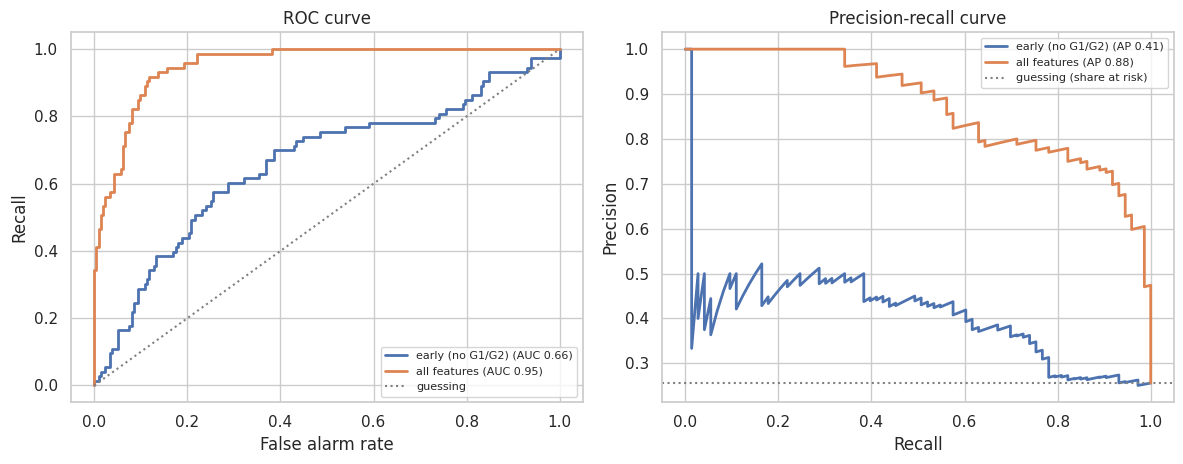

In [301]:
# Cell 135: ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for fname, p in proba.items():
    fpr, tpr, _ = roc_curve(y, p)
    axes[0].plot(fpr, tpr, linewidth=2, label=f"{fname} (AUC {roc_auc_score(y, p):.2f})")
    pr, rc, _ = precision_recall_curve(y, p)
    axes[1].plot(rc, pr, linewidth=2, label=f"{fname} (AP {average_precision_score(y, p):.2f})")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle=":", label="guessing")
axes[0].set_xlabel("False alarm rate"); axes[0].set_ylabel("Recall"); axes[0].set_title("ROC curve")
axes[1].axhline(y.mean(), color="gray", linestyle=":", label="guessing (share at risk)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curve")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [302]:
# Cell 136: the threshold decides the trade-off
rows = []
for fname, p in proba.items():
    for t in [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6]:
        flag = (p >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, flag).ravel()
        rows.append({"features": fname, "threshold": t,
                     "flagged %": round(flag.mean() * 100, 1),
                     "caught": tp, "missed": fn, "false alarms": fp,
                     "precision": round(precision_score(y, flag, zero_division=0), 2),
                     "recall": round(recall_score(y, flag), 2)})
threshold_table = pd.DataFrame(rows)
threshold_table

# the highest threshold that still catches at least 80% of at-risk students
print()
for fname, p in proba.items():
    ok = [t for t in np.linspace(0.01, 0.99, 99) if recall_score(y, (p >= t).astype(int)) >= 0.80]
    if ok:
        t = max(ok); flag = (p >= t).astype(int)
        print(f"{fname}: threshold {t:.2f} -> flags {flag.mean():.0%} of students, "
              f"precision {precision_score(y, flag):.2f}, recall {recall_score(y, flag):.2f}")
    else:
        print(f"{fname}: no threshold reaches 80% recall")


early (no G1/G2): threshold 0.05 -> flags 79% of students, precision 0.27, recall 0.82
all features: threshold 0.36 -> flags 27% of students, precision 0.78, recall 0.81


In [303]:
# Cell 137: class_weight="balanced" makes the model care more about the at-risk group
rows = {}
for fname, X in feature_sets.items():
    p_bal = cross_val_predict(make_lr(class_weight="balanced"), X, y, cv=skf, method="predict_proba")[:, 1]
    rows[f"{fname}, default"] = metrics_at(proba[fname])
    rows[f"{fname}, balanced"] = metrics_at(p_bal)
pd.DataFrame(rows).T

,flagged,accuracy,precision,recall,F1,ROC AUC,PR AUC
"early (no G1/G2), default",45.0,0.740,0.489,0.301,0.373,0.662,0.412
"early (no G1/G2), balanced",102.0,0.688,0.422,0.589,0.491,0.671,0.409
"all features, default",65.0,0.881,0.800,0.712,0.754,0.954,0.878
"all features, balanced",77.0,0.888,0.766,0.808,0.787,0.955,0.883


In [304]:
# Cell 138: tune C inside nested cross-validation (small C = strong regularisation)
grid = {"logisticregression__C": np.logspace(-3, 2, 20)}
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

rows = []
for fname, X in feature_sets.items():
    gs = GridSearchCV(make_lr(), grid, cv=skf, scoring="roc_auc", n_jobs=-1).fit(X, y)
    nested = cross_val_score(GridSearchCV(make_lr(), grid, cv=skf, scoring="roc_auc", n_jobs=-1),
                             X, y, cv=outer, scoring="roc_auc")
    default = cross_val_score(make_lr(), X, y, cv=outer, scoring="roc_auc")
    rows.append({"features": fname,
                 "best C": round(gs.best_params_["logisticregression__C"], 3),
                 "default AUC": round(default.mean(), 3),
                 "tuned AUC (nested, honest)": round(nested.mean(), 3)})
pd.DataFrame(rows)

,features,best C,default AUC,"tuned AUC (nested, honest)"
0,early (no G1/G2),0.070,0.672,0.672
1,all features,2.637,0.961,0.946


In [305]:
# Cell 139: classifier vs flagging from the Ridge grade prediction (Day 13 idea)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for fname, X in feature_sets.items():
    pred_grade = cross_val_predict(make_pipeline(StandardScaler(), Ridge(alpha=10)), X, y_grade, cv=kf)
    rows.append({"features": fname,
                 "AUC, Ridge predicted grade": round(roc_auc_score(y, -pred_grade), 3),
                 "AUC, logistic probability": round(roc_auc_score(y, proba[fname]), 3)})
pd.DataFrame(rows)

,features,"AUC, Ridge predicted grade","AUC, logistic probability"
0,early (no G1/G2),0.720,0.662
1,all features,0.968,0.954


Odds ratio per 1 standard deviation increase (above 1 = more at risk, below 1 = less):
goout            1.85
absences         1.80
schoolsup        1.63
failures         1.54
famsup           1.49
age              1.35
Mjob_services    0.66
Mjob_teacher     1.32


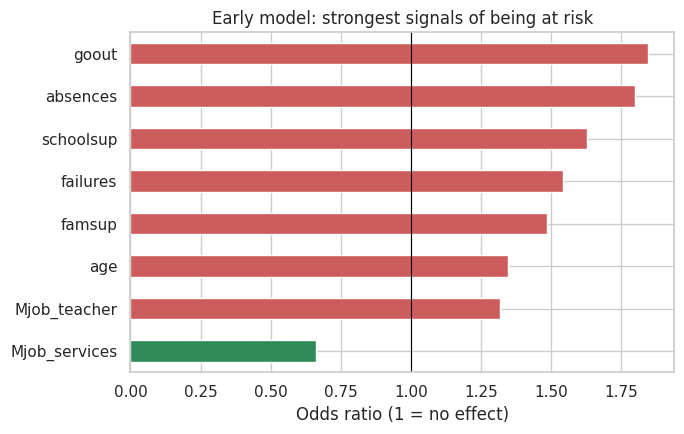


All-features model, odds ratio for G2: 0.02


In [306]:
# Cell 140: what drives risk? Odds ratios from the early model
model = make_lr().fit(X_early, y)
coef = pd.Series(model[-1].coef_[0], index=X_early.columns)
odds = np.exp(coef)
top = odds.reindex((odds - 1).abs().sort_values(ascending=False).index).head(8)

print("Odds ratio per 1 standard deviation increase (above 1 = more at risk, below 1 = less):")
print(top.round(2).to_string())

plt.figure(figsize=(7, 4.5))
top.sort_values().plot(kind="barh", color=np.where(top.sort_values() > 1, "indianred", "seagreen"))
plt.axvline(1, color="black", linewidth=0.8)
plt.xlabel("Odds ratio (1 = no effect)")
plt.title("Early model: strongest signals of being at risk")
plt.tight_layout()
plt.savefig("odds_ratios.png", dpi=150, bbox_inches="tight")
plt.show()

model_all = make_lr().fit(X_all, y)
print("\nAll-features model, odds ratio for G2:",
      round(float(np.exp(model_all[-1].coef_[0][list(X_all.columns).index("G2")])), 2))

In [307]:
# Cell 141: save the results for the final report
results.to_csv("classification_results.csv")
threshold_table.to_csv("threshold_table.csv", index=False)
print("Saved classification_results.csv and threshold_table.csv")
print(results.to_string())

Saved classification_results.csv and threshold_table.csv
                  flagged  accuracy  precision  recall     F1  ROC AUC  PR AUC
early (no G1/G2)     45.0     0.740      0.489   0.301  0.373    0.662   0.412
all features         65.0     0.881      0.800   0.712  0.754    0.954   0.878


In [308]:
# Cell 142: setup, one set of folds for everything
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (RepeatedKFold, RepeatedStratifiedKFold, KFold,
                                     StratifiedKFold, GridSearchCV, cross_validate)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import make_scorer, precision_score, f1_score
from linreg_scratch import LinearRegressionScratch      # your Day 11 file

sns.set_theme(style="whitegrid")
train = pd.read_csv("train.csv")
y = train["G3"]
y_risk = (y < 10).astype(int)
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

cv_reg = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
cv_clf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
inner_reg = KFold(n_splits=5, shuffle=True, random_state=1)
inner_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

print("Training students:", len(train), "| at risk:", y_risk.sum(), f"({y_risk.mean():.1%})")
print("Scores per model: 5 folds x 3 repeats = 15")

Training students: 285 | at risk: 73 (25.6%)
Scores per model: 5 folds x 3 repeats = 15


In [309]:
# Cell 143: the regression models, every tuned one is tuned INSIDE each outer fold (nested CV)
tree_grid = {"max_depth": [2, 3, 4, 5, 6, 8], "min_samples_leaf": [1, 5, 10, 20]}

reg_models = {
    "Baseline (mean)": DummyRegressor(),
    "Linear": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 40))),
    "Lasso": make_pipeline(StandardScaler(),
                           LassoCV(alphas=np.logspace(-3, 0.5, 30), cv=5, max_iter=20000)),
    "Tree (tuned)": GridSearchCV(DecisionTreeRegressor(random_state=42), tree_grid,
                                 cv=inner_reg, scoring="neg_root_mean_squared_error", n_jobs=-1),
}
reg_scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

In [310]:
# Cell 144: run every regression model on both feature sets
fold_scores = {}
for fname, X in feature_sets.items():
    for mname, m in reg_models.items():
        r = cross_validate(m, X, y, cv=cv_reg, scoring=reg_scoring)
        fold_scores[(fname, mname)] = {"rmse": -r["test_rmse"], "mae": -r["test_mae"], "r2": r["test_r2"]}

    # your from-scratch model from Day 11, on exactly the same folds
    rm, ma, r2 = [], [], []
    for tr, va in cv_reg.split(X):
        m = LinearRegressionScratch(lr=0.05, epochs=3000).fit(X.iloc[tr], y.iloc[tr])
        p, yt = m.predict(X.iloc[va]), y.iloc[va].values
        rm.append(np.sqrt(np.mean((yt - p) ** 2)))
        ma.append(np.mean(np.abs(yt - p)))
        r2.append(1 - np.sum((yt - p) ** 2) / np.sum((yt - yt.mean()) ** 2))
    fold_scores[(fname, "Linear (from scratch)")] = {"rmse": np.array(rm), "mae": np.array(ma), "r2": np.array(r2)}

rows = []
for (fname, mname), s in fold_scores.items():
    base_mae = fold_scores[(fname, "Baseline (mean)")]["mae"].mean()
    rows.append({"features": fname, "model": mname,
                 "RMSE": s["rmse"].mean(), "RMSE std": s["rmse"].std(),
                 "MAE": s["mae"].mean(), "R2": s["r2"].mean(),
                 "scaled MAE": s["mae"].mean() / base_mae})
reg_table = pd.DataFrame(rows).round(3)
reg_table.sort_values(["features", "RMSE"]).reset_index(drop=True)

,features,model,RMSE,RMSE std,MAE,R2,scaled MAE
0,all features,Lasso,0.836,0.080,0.650,0.932,0.244
1,all features,Ridge,0.903,0.082,0.730,0.920,0.274
2,all features,Linear,0.905,0.083,0.731,0.920,0.275
3,all features,Linear (from scratch),0.905,0.083,0.731,0.920,0.275
4,all features,Tree (tuned),0.974,0.101,0.769,0.907,0.289
5,all features,Baseline (mean),3.267,0.124,2.662,-0.030,1.000
6,early (no G1/G2),Lasso,2.960,0.136,2.423,0.151,0.910
7,early (no G1/G2),Ridge,2.966,0.130,2.404,0.148,0.903
8,early (no G1/G2),Linear,3.060,0.207,2.450,0.087,0.920
9,early (no G1/G2),Linear (from scratch),3.060,0.207,2.450,0.087,0.920


In [311]:
# Cell 145: is each model really better than the baseline? Paired comparison on the SAME folds
rows = []
for fname in feature_sets:
    base = fold_scores[(fname, "Baseline (mean)")]["rmse"]
    for (f, mname), s in fold_scores.items():
        if f != fname or mname == "Baseline (mean)":
            continue
        diff = base - s["rmse"]
        rows.append({"features": fname, "model": mname,
                     "gain over baseline (grade pts)": round(diff.mean(), 3),
                     "relative gain %": round(100 * diff.mean() / base.mean(), 1),
                     "folds better": f"{(diff > 0).sum()}/{len(diff)}"})
paired_tbl = pd.DataFrame(rows)
paired_tbl

print("\nBeating the baseline in most folds is descriptive evidence, not a formal test:")
print("the 15 folds share students, so they are not fully independent.")


Beating the baseline in most folds is descriptive evidence, not a formal test:
the 15 folds share students, so they are not fully independent.


In [312]:
# Cell 146: the selection rule, written down so it can be defended
rank = {"Linear": 1, "Ridge": 1, "Lasso": 2, "Tree (tuned)": 3}   # lower = simpler

chosen_reg = {}
for fname in feature_sets:
    cand = reg_table[(reg_table.features == fname) & reg_table.model.isin(list(rank))]
    best = cand.loc[cand["RMSE"].idxmin()]
    ok = cand[cand["RMSE"] <= best["RMSE"] + best["RMSE std"]].copy()     # within 1 std of the best
    ok["rank"] = ok["model"].map(rank)
    pick = ok.sort_values(["rank", "RMSE"]).iloc[0]

    pr = paired_tbl[(paired_tbl.features == fname) & (paired_tbl.model == pick["model"])].iloc[0]
    better, total = [int(v) for v in pr["folds better"].split("/")]
    useful = (better / total >= 0.8) and (pr["relative gain %"] >= 10)

    chosen_reg[fname] = {"model": pick["model"], "cv_rmse": float(pick["RMSE"]),
                         "relative_gain_pct": float(pr["relative gain %"]),
                         "folds_better": pr["folds better"], "useful": bool(useful)}
    print(f"{fname:18s} best: {best['model']} ({best['RMSE']:.3f}) | "
          f"models within 1 std: {list(ok['model'])}")
    print(f"{'':18s} CHOSEN: {pick['model']} | RMSE {pick['RMSE']:.3f} | "
          f"{pr['relative gain %']}% better than baseline in {pr['folds better']} folds | "
          f"useful: {useful}\n")

early (no G1/G2)   best: Lasso (2.960) | models within 1 std: ['Linear', 'Ridge', 'Lasso']
                   CHOSEN: Ridge | RMSE 2.966 | 9.2% better than baseline in 15/15 folds | useful: False

all features       best: Lasso (0.836) | models within 1 std: ['Linear', 'Ridge', 'Lasso']
                   CHOSEN: Ridge | RMSE 0.903 | 72.4% better than baseline in 15/15 folds | useful: True



In [313]:
# Cell 147: the classification models (same idea, scored on the at-risk flag)
clf_models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "Logistic (balanced)": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=5000, class_weight="balanced")),
    "Logistic (tuned C)": GridSearchCV(
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
        {"logisticregression__C": np.logspace(-3, 2, 12)},
        cv=inner_clf, scoring="roc_auc", n_jobs=-1),
}
clf_scoring = {"auc": "roc_auc", "ap": "average_precision", "recall": "recall",
               "precision": make_scorer(precision_score, zero_division=0),
               "f1": make_scorer(f1_score, zero_division=0)}

rows = []
for fname, X in feature_sets.items():
    for mname, m in clf_models.items():
        r = cross_validate(m, X, y_risk, cv=cv_clf, scoring=clf_scoring)
        rows.append({"features": fname, "model": mname,
                     "ROC AUC": r["test_auc"].mean(), "AUC std": r["test_auc"].std(),
                     "PR AUC": r["test_ap"].mean(),
                     "recall@0.5": r["test_recall"].mean(),
                     "precision@0.5": r["test_precision"].mean(),
                     "F1@0.5": r["test_f1"].mean()})
clf_table = pd.DataFrame(rows).round(3)
clf_table

,features,model,ROC AUC,AUC std,PR AUC,recall@0.5,precision@0.5,F1@0.5
0,early (no G1/G2),Baseline (most frequent),0.500,0.000,0.256,0.000,0.000,0.000
1,early (no G1/G2),Logistic,0.652,0.085,0.442,0.303,0.460,0.357
2,early (no G1/G2),Logistic (balanced),0.658,0.085,0.432,0.560,0.406,0.469
3,early (no G1/G2),Logistic (tuned C),0.664,0.078,0.460,0.082,0.318,0.123
4,all features,Baseline (most frequent),0.500,0.000,0.256,0.000,0.000,0.000
5,all features,Logistic,0.951,0.030,0.876,0.738,0.825,0.774
6,all features,Logistic (balanced),0.953,0.030,0.885,0.835,0.759,0.789
7,all features,Logistic (tuned C),0.942,0.030,0.860,0.670,0.799,0.708


In [314]:
# Cell 148: choose the classifier with the same logic (AUC, simplest within 1 std of the best)
crank = {"Logistic": 1, "Logistic (balanced)": 2, "Logistic (tuned C)": 3}
chosen_clf = {}
for fname in feature_sets:
    cand = clf_table[(clf_table.features == fname) & clf_table.model.isin(list(crank))]
    best = cand.loc[cand["ROC AUC"].idxmax()]
    ok = cand[cand["ROC AUC"] >= best["ROC AUC"] - best["AUC std"]].copy()
    ok["rank"] = ok["model"].map(crank)
    pick = ok.sort_values(["rank", "ROC AUC"], ascending=[True, False]).iloc[0]
    base_ap = clf_table[(clf_table.features == fname) &
                        (clf_table.model == "Baseline (most frequent)")]["PR AUC"].iloc[0]
    chosen_clf[fname] = {"model": pick["model"], "roc_auc": float(pick["ROC AUC"]),
                         "pr_auc": float(pick["PR AUC"]), "pr_auc_of_guessing": float(base_ap),
                         "usable": bool(pick["ROC AUC"] >= 0.70)}
    print(f"{fname:18s} CHOSEN: {pick['model']} | ROC AUC {pick['ROC AUC']:.3f} "
          f"| PR AUC {pick['PR AUC']:.3f} (guessing = {base_ap:.3f}) "
          f"| usable (AUC >= 0.70): {pick['ROC AUC'] >= 0.70}")

early (no G1/G2)   CHOSEN: Logistic | ROC AUC 0.652 | PR AUC 0.442 (guessing = 0.256) | usable (AUC >= 0.70): False
all features       CHOSEN: Logistic | ROC AUC 0.951 | PR AUC 0.876 (guessing = 0.256) | usable (AUC >= 0.70): True


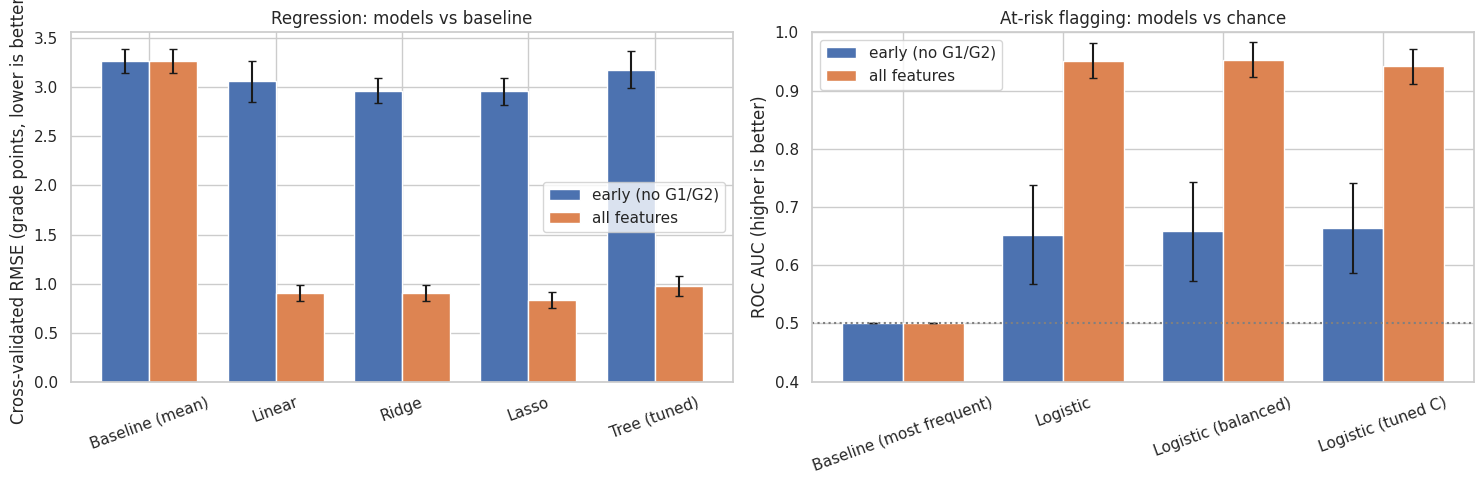

In [315]:
# Cell 149: one summary figure for the report
models_order = ["Baseline (mean)", "Linear", "Ridge", "Lasso", "Tree (tuned)"]
clf_order = ["Baseline (most frequent)", "Logistic", "Logistic (balanced)", "Logistic (tuned C)"]
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for i, fname in enumerate(feature_sets):
    sub = reg_table[reg_table.features == fname].set_index("model").loc[models_order]
    axes[0].bar(np.arange(len(models_order)) + i * width, sub["RMSE"], width,
                yerr=sub["RMSE std"], capsize=3, label=fname)
axes[0].set_xticks(np.arange(len(models_order)) + width / 2)
axes[0].set_xticklabels(models_order, rotation=20)
axes[0].set_ylabel("Cross-validated RMSE (grade points, lower is better)")
axes[0].set_title("Regression: models vs baseline"); axes[0].legend()

for i, fname in enumerate(feature_sets):
    sub = clf_table[clf_table.features == fname].set_index("model").loc[clf_order]
    axes[1].bar(np.arange(len(clf_order)) + i * width, sub["ROC AUC"], width,
                yerr=sub["AUC std"], capsize=3, label=fname)
axes[1].axhline(0.5, color="gray", linestyle=":")
axes[1].set_xticks(np.arange(len(clf_order)) + width / 2)
axes[1].set_xticklabels(clf_order, rotation=20)
axes[1].set_ylabel("ROC AUC (higher is better)"); axes[1].set_ylim(0.4, 1.0)
axes[1].set_title("At-risk flagging: models vs chance"); axes[1].legend()
plt.tight_layout()
plt.savefig("phase3_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [316]:
# Cell 150: save everything. These files feed Phase 4 and the final report.
reg_table.to_csv("phase3_regression_results.csv", index=False)
clf_table.to_csv("phase3_classification_results.csv", index=False)
paired_tbl.to_csv("phase3_paired_comparison.csv", index=False)

chosen = {"regression": chosen_reg, "classification": chosen_clf,
          "cv": "5-fold x 3 repeats, random_state=42",
          "rules": {"selection": "simplest model within 1 std of the best",
                    "regression_useful": ">=80% folds better than baseline and >=10% lower RMSE",
                    "classification_usable": "ROC AUC >= 0.70"}}
with open("chosen_baselines.json", "w") as f:
    json.dump(chosen, f, indent=2)
print(json.dumps(chosen, indent=2))

{
  "regression": {
    "early (no G1/G2)": {
      "model": "Ridge",
      "cv_rmse": 2.966,
      "relative_gain_pct": 9.2,
      "folds_better": "15/15",
      "useful": false
    },
    "all features": {
      "model": "Ridge",
      "cv_rmse": 0.903,
      "relative_gain_pct": 72.4,
      "folds_better": "15/15",
      "useful": true
    }
  },
  "classification": {
    "early (no G1/G2)": {
      "model": "Logistic",
      "roc_auc": 0.652,
      "pr_auc": 0.442,
      "pr_auc_of_guessing": 0.256,
      "usable": false
    },
    "all features": {
      "model": "Logistic",
      "roc_auc": 0.951,
      "pr_auc": 0.876,
      "pr_auc_of_guessing": 0.256,
      "usable": true
    }
  },
  "cv": "5-fold x 3 repeats, random_state=42",
  "rules": {
    "selection": "simplest model within 1 std of the best",
    "regression_useful": ">=80% folds better than baseline and >=10% lower RMSE",
    "classification_usable": "ROC AUC >= 0.70"
  }
}
